# Bayesian photon-flux surrogate for UPCs
## Sobol-only minimum resubmission notebook with an analytical EDFF baseline

This notebook is a cleaned continuation of `bayesian-photon-flux-13.ipynb`. It remains a **single linear notebook** so that a student can run it from top to bottom without having to coordinate several files.

### Scientific objective

Train and validate an MC-dropout surrogate for the finite-size equivalent-photon flux

\[
N_{\rm finite}(\omega,b;\Delta R,a)
\]

over a four-dimensional Pb--Pb domain. The network does **not** learn the full flux directly. Instead it learns the smoother finite-size correction to the analytical electric-dipole-form-factor flux,

\[
c(\omega,b;\Delta R,a)
=
\log\frac{N_{\rm finite}(\omega,b;\Delta R,a)}
{N_{\rm EDFF}(\omega,b)}.
\]

The predicted flux is reconstructed as

\[
N_{\rm surrogate}=N_{\rm EDFF}\exp(c_{\rm NN}).
\]

This factorisation gives the network an analytical baseline containing the dominant \((\omega,b)\) dependence and leaves it to learn the nuclear finite-size correction.

### Minimum resubmission evidence produced here

1. numerical convergence and normalisation checks;
2. direct comparison of the numerical finite-size EPA flux with the analytical EDFF;
3. a padded Sobol training domain and an independent reported test domain;
4. multidimensional residual and calibration diagnostics;
5. direct numerical validation of nuclear-parameter uncertainty;
6. separated surrogate-epistemic and nuclear-parameter uncertainties;
7. a Sobol sample-size convergence study, replacing the unsupported active-learning claim;
8. an impact-parameter-integrated flux application;
9. transparent speed and break-even benchmarks.

### Important conventions

- The working convention `R0 = R0_BASE + delta_r` is retained from the original project and must be physically justified in the manuscript.
- Lengths are in fm and energies in GeV. The factor \(\hbar c\) is explicit in \(\xi=\omega b/(\gamma\hbar c)\).
- The analytical EDFF expression is Eq. (11) of Shao and d'Enterria, JHEP 09 (2022) 248, arXiv:2207.03012.
- The reported validity interval is \(y\in[-4,4]\), but training is padded to \(y\in[-4.5,4.5]\) so that reported endpoints are not ML boundaries.
- MC dropout is treated as an approximate epistemic-uncertainty method and is calibrated only with the validation set.
- Sobol sampling is the production strategy. No active-learning efficiency claim is made.


## 1. Imports, reproducibility and run configuration

All important numerical and ML choices are collected in one configuration object. Publication sample sizes are powers of two to preserve the balance properties of Sobol sampling.


In [1]:
# Uncomment only when the environment is missing packages.
# %pip install numpy scipy pandas matplotlib tensorflow tqdm

from __future__ import annotations

import hashlib
import json
import math
import os
import platform
import random
import sys
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from numpy.polynomial.legendre import leggauss
from scipy.special import kv
from scipy.stats import norm, qmc

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, **kwargs):
        return iterable

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

MODE = "publication"  # use "student" only for a quick end-to-end test
SEED = 260210692

np.random.seed(SEED)
random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

OUTPUT_DIR = Path("bnn_flux_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("TensorFlow:", tf.__version__)


Python: 3.12.15
Platform: macOS-26.6.2-arm64-arm-64bit
NumPy: 2.5.4
SciPy: 1.18.1
TensorFlow: 2.21.0


In [2]:
@dataclass(frozen=True)
class RunConfig:
    mode: str

    # Train outside the reported interval to avoid evaluating at an ML boundary.
    y_train_min: float
    y_train_max: float
    y_report_min: float
    y_report_max: float
    b_min_fm: float
    b_hard_max_fm: float
    xi_max: float
    prior_widths: float

    # Fixed Gauss-Legendre quadrature
    n_r: int
    n_phi: int
    n_z: int
    n_norm: int
    tail_widths: float

    # Sobol train/validation/test samples
    n_train: int
    n_val: int
    n_test: int

    # Neural network
    hidden_units: tuple[int, ...]
    dropout_rate: float
    learning_rate: float
    batch_size: int
    epochs: int
    patience: int
    mc_passes: int

    # Sobol sample-size convergence study
    run_sample_size_study: bool
    sample_size_study_sizes: tuple[int, ...]
    sample_size_study_epochs: int
    sample_size_mc_passes: int

    # Final demonstrations
    uncertainty_nuclear_samples: int
    nuclear_direct_validation_samples: int
    integrated_y_points: int
    integrated_b_nodes: int


if MODE == "student":
    CFG = RunConfig(
        mode=MODE,
        y_train_min=-4.5,
        y_train_max=4.5,
        y_report_min=-4.0,
        y_report_max=4.0,
        b_min_fm=14.0,
        b_hard_max_fm=300_000.0,
        xi_max=8.0,
        prior_widths=3.0,
        n_r=32,
        n_phi=48,
        n_z=48,
        n_norm=80,
        tail_widths=12.0,
        n_train=512,
        n_val=256,
        n_test=512,
        hidden_units=(128, 128, 64),
        dropout_rate=0.05,
        learning_rate=1.0e-3,
        batch_size=64,
        epochs=300,
        patience=35,
        mc_passes=80,
        run_sample_size_study=False,
        sample_size_study_sizes=(128, 256, 512),
        sample_size_study_epochs=300,
        sample_size_mc_passes=40,
        uncertainty_nuclear_samples=128,
        nuclear_direct_validation_samples=64,
        integrated_y_points=9,
        integrated_b_nodes=32,
    )
elif MODE == "publication":
    CFG = RunConfig(
        mode=MODE,
        y_train_min=-4.5,
        y_train_max=4.5,
        y_report_min=-4.0,
        y_report_max=4.0,
        b_min_fm=14.0,
        b_hard_max_fm=300_000.0,
        xi_max=8.0,
        prior_widths=3.0,
        n_r=48,
        n_phi=72,
        n_z=64,
        n_norm=120,
        tail_widths=14.0,
        n_train=65536,
        n_val=2048,
        n_test=4096,
        hidden_units=(256, 256, 128, 64),
        dropout_rate=0.05,
        learning_rate=5.0e-4,
        batch_size=256,
        epochs=800,
        patience=80,
        mc_passes=200,
        run_sample_size_study=True,
        sample_size_study_sizes=(1024, 2048, 4096, 8192, 16384, 32768, 65536),
        sample_size_study_epochs=800,
        sample_size_mc_passes=80,
        uncertainty_nuclear_samples=512,
        nuclear_direct_validation_samples=256,
        integrated_y_points=17,
        integrated_b_nodes=64,
    )
else:
    raise ValueError("MODE must be 'student' or 'publication'.")

if CFG.sample_size_study_sizes[-1] != CFG.n_train:
    raise ValueError("The largest sample-size-study value must equal n_train.")

print(CFG)
with open(OUTPUT_DIR / f"config_{MODE}.json", "w") as stream:
    json.dump(asdict(CFG), stream, indent=2)


RunConfig(mode='publication', y_train_min=-4.5, y_train_max=4.5, y_report_min=-4.0, y_report_max=4.0, b_min_fm=14.0, b_hard_max_fm=300000.0, xi_max=8.0, prior_widths=3.0, n_r=48, n_phi=72, n_z=64, n_norm=120, tail_widths=14.0, n_train=65536, n_val=2048, n_test=4096, hidden_units=(256, 256, 128, 64), dropout_rate=0.05, learning_rate=0.0005, batch_size=256, epochs=800, patience=80, mc_passes=200, run_sample_size_study=True, sample_size_study_sizes=(1024, 2048, 4096, 8192, 16384, 32768, 65536), sample_size_study_epochs=800, sample_size_mc_passes=80, uncertainty_nuclear_samples=512, nuclear_direct_validation_samples=256, integrated_y_points=17, integrated_b_nodes=64)


## 2. Physics constants and parameter domains

The surrogate is trained on a rectangular nuclear-parameter domain and on an energy-dependent impact-parameter domain. Gaussian priors are used **only** when propagating physical uncertainty.

The submitted manuscript used a diffuseness uncertainty of \(0.015\) fm; that value is used consistently here.


In [3]:
# Physical constants
ALPHA_EM = 1.0 / 137.035999084
Z_ION = 82
GAMMA_BEAM = 2950.0
HBARC_GEV_FM = 0.1973269804
M_JPSI_GEV = 3.0969

# Woods-Saxon parameter convention retained from the original notebook
R0_BASE_FM = 6.62
DELTA_R_MEAN_FM = 0.283
DELTA_R_SIGMA_FM = 0.071
A_MEAN_FM = 0.546
A_SIGMA_FM = 0.015

DELTA_R_MIN_FM = DELTA_R_MEAN_FM - CFG.prior_widths * DELTA_R_SIGMA_FM
DELTA_R_MAX_FM = DELTA_R_MEAN_FM + CFG.prior_widths * DELTA_R_SIGMA_FM
A_MIN_FM = A_MEAN_FM - CFG.prior_widths * A_SIGMA_FM
A_MAX_FM = A_MEAN_FM + CFG.prior_widths * A_SIGMA_FM


def rapidity_to_omega(y: np.ndarray | float) -> np.ndarray:
    return 0.5 * M_JPSI_GEV * np.exp(np.asarray(y, dtype=float))


def omega_to_rapidity(omega_gev: np.ndarray | float) -> np.ndarray:
    return np.log(2.0 * np.asarray(omega_gev, dtype=float) / M_JPSI_GEV)


OMEGA_TRAIN_MIN_GEV = float(rapidity_to_omega(CFG.y_train_min))
OMEGA_TRAIN_MAX_GEV = float(rapidity_to_omega(CFG.y_train_max))
OMEGA_REPORT_MIN_GEV = float(rapidity_to_omega(CFG.y_report_min))
OMEGA_REPORT_MAX_GEV = float(rapidity_to_omega(CFG.y_report_max))

LOG_OMEGA_TRAIN_MIN = math.log(OMEGA_TRAIN_MIN_GEV)
LOG_OMEGA_TRAIN_MAX = math.log(OMEGA_TRAIN_MAX_GEV)
LOG_OMEGA_REPORT_MIN = math.log(OMEGA_REPORT_MIN_GEV)
LOG_OMEGA_REPORT_MAX = math.log(OMEGA_REPORT_MAX_GEV)


def radius_from_delta_r(delta_r_fm: np.ndarray | float) -> np.ndarray:
    """Project convention: R0 = R0_BASE + delta_r. Verify physically before submission."""
    return R0_BASE_FM + np.asarray(delta_r_fm, dtype=float)


LOG_B_MIN = math.log(CFG.b_min_fm)
LOG_B_HARD_MAX = math.log(CFG.b_hard_max_fm)


def b_max_for_omega(
    omega_gev: np.ndarray | float,
    *,
    xi_max: float | None = None,
    hard_max_fm: float | None = None,
) -> np.ndarray:
    """Upper b boundary chosen so the Bessel-kernel tail is truncated at xi_max."""
    xi_max = CFG.xi_max if xi_max is None else xi_max
    hard_max_fm = CFG.b_hard_max_fm if hard_max_fm is None else hard_max_fm
    omega = np.asarray(omega_gev, dtype=float)
    kinematic_max = xi_max * GAMMA_BEAM * HBARC_GEV_FM / omega
    return np.maximum(CFG.b_min_fm, np.minimum(hard_max_fm, kinematic_max))


FEATURE_DOMAIN = {
    "log_omega": (LOG_OMEGA_TRAIN_MIN, LOG_OMEGA_TRAIN_MAX),
    "log_b": (LOG_B_MIN, LOG_B_HARD_MAX),
    "delta_r_fm": (DELTA_R_MIN_FM, DELTA_R_MAX_FM),
    "a_fm": (A_MIN_FM, A_MAX_FM),
}

domain_table = pd.DataFrame(
    {
        "training_minimum": [
            CFG.y_train_min,
            CFG.b_min_fm,
            DELTA_R_MIN_FM,
            A_MIN_FM,
        ],
        "training_maximum": [
            CFG.y_train_max,
            CFG.b_hard_max_fm,
            DELTA_R_MAX_FM,
            A_MAX_FM,
        ],
        "reported_minimum": [
            CFG.y_report_min,
            CFG.b_min_fm,
            DELTA_R_MIN_FM,
            A_MIN_FM,
        ],
        "reported_maximum": [
            CFG.y_report_max,
            CFG.b_hard_max_fm,
            DELTA_R_MAX_FM,
            A_MAX_FM,
        ],
    },
    index=["rapidity_proxy_y", "b_fm_global_bound", "delta_r_fm", "a_fm"],
)
display(domain_table)
print(
    "Energy-dependent b maxima at training y endpoints:",
    float(b_max_for_omega(OMEGA_TRAIN_MIN_GEV)),
    float(b_max_for_omega(OMEGA_TRAIN_MAX_GEV)),
    "fm",
)
print(
    "Energy-dependent b maxima at reported y endpoints:",
    float(b_max_for_omega(OMEGA_REPORT_MIN_GEV)),
    float(b_max_for_omega(OMEGA_REPORT_MAX_GEV)),
    "fm",
)


,training_minimum,training_maximum,reported_minimum,reported_maximum
rapidity_proxy_y,-4.500,4.500,-4.000,4.000
b_fm_global_bound,14.000,300000.000,14.000,300000.000
delta_r_fm,0.070,0.496,0.070,0.496
a_fm,0.501,0.591,0.501,0.591


Energy-dependent b maxima at training y endpoints: 270723.81117229105 33.409972498371665 fm
Energy-dependent b maxima at reported y endpoints: 164202.2917902481 55.083732311571666 fm


## 3. Deterministic finite-size EPA integrator

The numerical target is a finite-size real-space convolution. For comparison, the analytical EDFF number density is

\[
N_{\gamma/Z}^{\rm EDFF}(\omega,b)
=
\frac{Z^2\alpha}{\pi^2}
\frac{\xi^2}{b^2}
\left[
K_1^2(\xi)+\frac{1}{\gamma^2}K_0^2(\xi)
\right],
\qquad
\xi=\frac{\omega b}{\gamma\hbar c}.
\]

The three-dimensional Woods--Saxon density is normalised separately for every \((R_0,a)\), and all numerical integrations use fixed Gauss--Legendre quadrature.


In [4]:
def gauss_legendre_interval(lower: float, upper: float, n_points: int) -> tuple[np.ndarray, np.ndarray]:
    """Nodes and weights for an n-point Gauss-Legendre integral on [lower, upper]."""
    nodes, weights = leggauss(n_points)
    mapped_nodes = 0.5 * (upper - lower) * nodes + 0.5 * (upper + lower)
    mapped_weights = 0.5 * (upper - lower) * weights
    return mapped_nodes, mapped_weights


def woods_saxon_shape(r_fm: np.ndarray, r0_fm: float, a_fm: float) -> np.ndarray:
    exponent = np.clip((np.asarray(r_fm) - r0_fm) / a_fm, -700.0, 700.0)
    return 1.0 / (1.0 + np.exp(exponent))


def woods_saxon_3d_normalisation(
    r0_fm: float,
    a_fm: float,
    *,
    n_norm: int | None = None,
    tail_widths: float | None = None,
) -> float:
    """Return 4*pi*integral r^2 f(r)dr for the unnormalised Woods-Saxon shape."""
    n_norm = CFG.n_norm if n_norm is None else n_norm
    tail_widths = CFG.tail_widths if tail_widths is None else tail_widths
    r_max = r0_fm + tail_widths * a_fm
    r_nodes, r_weights = gauss_legendre_interval(0.0, r_max, n_norm)
    return float(4.0 * np.pi * np.sum(r_weights * r_nodes**2 * woods_saxon_shape(r_nodes, r0_fm, a_fm)))


def projected_density_at_nodes(
    transverse_r_fm: np.ndarray,
    r0_fm: float,
    a_fm: float,
    *,
    n_z: int | None = None,
    n_norm: int | None = None,
    tail_widths: float | None = None,
) -> np.ndarray:
    """Normalised projected density rho_2D(R) with integral d^2R rho_2D = 1."""
    n_z = CFG.n_z if n_z is None else n_z
    n_norm = CFG.n_norm if n_norm is None else n_norm
    tail_widths = CFG.tail_widths if tail_widths is None else tail_widths

    z_max = r0_fm + tail_widths * a_fm
    z_nodes, z_weights = gauss_legendre_interval(0.0, z_max, n_z)
    norm_3d = woods_saxon_3d_normalisation(
        r0_fm,
        a_fm,
        n_norm=n_norm,
        tail_widths=tail_widths,
    )

    radius_3d = np.sqrt(np.asarray(transverse_r_fm)[:, None] ** 2 + z_nodes[None, :] ** 2)
    rho_3d = woods_saxon_shape(radius_3d, r0_fm, a_fm) / norm_3d
    return 2.0 * np.sum(z_weights[None, :] * rho_3d, axis=1)


def analytical_edff_flux(
    omega_gev: float | np.ndarray,
    b_fm: float | np.ndarray,
    *,
    gamma: float = GAMMA_BEAM,
    z_ion: int = Z_ION,
    alpha_em: float = ALPHA_EM,
) -> np.ndarray:
    """Analytical EDFF photon number density in fm^-2."""
    b = np.maximum(np.asarray(b_fm, dtype=float), 1.0e-10)
    omega = np.asarray(omega_gev, dtype=float)
    xi = omega * b / (gamma * HBARC_GEV_FM)
    prefactor = (z_ion**2 * alpha_em) / (np.pi**2 * b**2) * xi**2
    return prefactor * (kv(1, xi) ** 2 + kv(0, xi) ** 2 / gamma**2)


def finite_size_epa_flux(
    omega_gev: float,
    b_fm: float,
    delta_r_fm: float,
    a_fm: float,
    *,
    n_r: int | None = None,
    n_phi: int | None = None,
    n_z: int | None = None,
    n_norm: int | None = None,
    tail_widths: float | None = None,
) -> float:
    """
    Finite-size flux from a real-space convolution:
      integral dphi integral R dR rho_2D(R) n_point(omega, |b + R|).
    """
    n_r = CFG.n_r if n_r is None else n_r
    n_phi = CFG.n_phi if n_phi is None else n_phi
    n_z = CFG.n_z if n_z is None else n_z
    n_norm = CFG.n_norm if n_norm is None else n_norm
    tail_widths = CFG.tail_widths if tail_widths is None else tail_widths

    r0_fm = float(radius_from_delta_r(delta_r_fm))
    r_max = r0_fm + tail_widths * a_fm
    r_nodes, r_weights = gauss_legendre_interval(0.0, r_max, n_r)
    phi_nodes, phi_weights = gauss_legendre_interval(0.0, 2.0 * np.pi, n_phi)

    rho_2d = projected_density_at_nodes(
        r_nodes,
        r0_fm,
        a_fm,
        n_z=n_z,
        n_norm=n_norm,
        tail_widths=tail_widths,
    )

    distance = np.sqrt(
        b_fm**2
        + r_nodes[:, None] ** 2
        + 2.0 * b_fm * r_nodes[:, None] * np.cos(phi_nodes)[None, :]
    )
    angular_integral = np.sum(
        phi_weights[None, :] * analytical_edff_flux(omega_gev, distance),
        axis=1,
    )
    flux = np.sum(r_weights * r_nodes * rho_2d * angular_integral)
    return float(flux)

# Compatibility alias used in a few diagnostic descriptions.
point_charge_epa_flux = analytical_edff_flux


def analytical_edff_integrated_flux(
    omega_gev: float | np.ndarray,
    *,
    b_min_fm: float = CFG.b_min_fm,
    gamma: float = GAMMA_BEAM,
    z_ion: int = Z_ION,
    alpha_em: float = ALPHA_EM,
) -> np.ndarray:
    """Analytical integral 2*pi*integral_{b_min}^infinity b db N_EDFF(omega,b)."""
    omega = np.asarray(omega_gev, dtype=float)
    chi = omega * b_min_fm / (gamma * HBARC_GEV_FM)
    k0 = kv(0, chi)
    k1 = kv(1, chi)
    bracket = chi * k0 * k1 - 0.5 * (1.0 - gamma**-2) * chi**2 * (k1**2 - k0**2)
    return (2.0 * z_ion**2 * alpha_em / np.pi) * bracket


## 4. Mandatory numerical checks

These checks must pass before generating any training labels. Publication tables should include the density normalisation, quadrature convergence and analytical-EDFF integration checks.


In [5]:
def projected_density_normalisation_check(
    delta_r_fm: float,
    a_fm: float,
    *,
    n_r: int | None = None,
) -> float:
    n_r = max(CFG.n_r, 64) if n_r is None else n_r
    r0_fm = float(radius_from_delta_r(delta_r_fm))
    r_max = r0_fm + CFG.tail_widths * a_fm
    r_nodes, r_weights = gauss_legendre_interval(0.0, r_max, n_r)
    rho_2d = projected_density_at_nodes(r_nodes, r0_fm, a_fm)
    return float(2.0 * np.pi * np.sum(r_weights * r_nodes * rho_2d))


normalisation_rows = []
for delta_r_test, a_test in [
    (DELTA_R_MIN_FM, A_MIN_FM),
    (DELTA_R_MEAN_FM, A_MEAN_FM),
    (DELTA_R_MAX_FM, A_MAX_FM),
]:
    integral = projected_density_normalisation_check(delta_r_test, a_test)
    normalisation_rows.append(
        {
            "delta_r_fm": delta_r_test,
            "a_fm": a_test,
            "integral_d2R_rho2D": integral,
            "absolute_error": abs(integral - 1.0),
        }
    )

normalisation_table = pd.DataFrame(normalisation_rows)
display(normalisation_table)
assert normalisation_table["absolute_error"].max() < 5.0e-4, "Projected-density normalisation failed."


,delta_r_fm,a_fm,integral_d2R_rho2D,absolute_error
0,0.070,0.501,1.000001,5.795380e-07
1,0.283,0.546,1.000001,6.415422e-07
2,0.496,0.591,1.000001,7.029998e-07


In [6]:
# Convergence at representative interior and boundary points.
convergence_points = [
    (rapidity_to_omega(CFG.y_report_min), float(b_max_for_omega(rapidity_to_omega(CFG.y_report_min))), DELTA_R_MIN_FM, A_MIN_FM),
    (rapidity_to_omega(0.0), 20.0, DELTA_R_MEAN_FM, A_MEAN_FM),
    (rapidity_to_omega(CFG.y_report_max), float(b_max_for_omega(rapidity_to_omega(CFG.y_report_max))), DELTA_R_MAX_FM, A_MAX_FM),
]

quadrature_levels = [
    (20, 32, 32, 64),
    (32, 48, 48, 80),
    (48, 72, 64, 120),
]

convergence_rows = []
for point_id, (omega, b_fm, delta_r, a_fm) in enumerate(convergence_points):
    values = []
    for n_r, n_phi, n_z, n_norm in quadrature_levels:
        value = finite_size_epa_flux(
            float(omega),
            b_fm,
            delta_r,
            a_fm,
            n_r=n_r,
            n_phi=n_phi,
            n_z=n_z,
            n_norm=n_norm,
            tail_widths=max(CFG.tail_widths, 12.0),
        )
        values.append(value)
    reference = values[-1]
    for level, (settings, value) in enumerate(zip(quadrature_levels, values)):
        convergence_rows.append(
            {
                "point": point_id,
                "level": level,
                "n_r_n_phi_n_z_n_norm": str(settings),
                "flux_fm^-2": value,
                "relative_to_finest": value / reference - 1.0,
            }
        )

convergence_table = pd.DataFrame(convergence_rows)
display(convergence_table)
convergence_table.to_csv(OUTPUT_DIR / f"quadrature_convergence_{MODE}.csv", index=False)


,point,level,n_r_n_phi_n_z_n_norm,flux_fm^-2,relative_to_finest
0,0,0,"(20, 32, 32, 64)",2.848827e-16,4.822602e-05
1,0,1,"(32, 48, 48, 80)",2.848690e-16,1.544518e-07
2,0,2,"(48, 72, 64, 120)",2.848689e-16,0.000000e+00
3,1,0,"(20, 32, 32, 64)",1.304605e-02,3.020824e-05
4,1,1,"(32, 48, 48, 80)",1.304566e-02,-5.122108e-08
5,1,2,"(48, 72, 64, 120)",1.304566e-02,0.000000e+00
6,2,0,"(20, 32, 32, 64)",4.201293e-09,9.467280e-06
7,2,1,"(32, 48, 48, 80)",4.201253e-09,-1.292881e-07
8,2,2,"(48, 72, 64, 120)",4.201253e-09,0.000000e+00


In [7]:
# At b much larger than the nuclear radius, the finite-size convolution must approach the point-charge result.
point_limit_rows = []
for y_value, b_value in [(-4.0, 5000.0), (0.0, 500.0)]:
    omega_value = float(rapidity_to_omega(y_value))
    finite_value = finite_size_epa_flux(
        omega_value,
        b_value,
        DELTA_R_MEAN_FM,
        A_MEAN_FM,
    )
    point_value = float(analytical_edff_flux(omega_value, b_value))
    point_limit_rows.append(
        {
            "y": y_value,
            "b_fm": b_value,
            "finite_size": finite_value,
            "analytical_edff": point_value,
            "relative_difference": finite_value / point_value - 1.0,
        }
    )
point_limit_table = pd.DataFrame(point_limit_rows)
display(point_limit_table)
assert np.max(np.abs(point_limit_table["relative_difference"])) < 1.0e-3


,y,b_fm,finite_size,analytical_edff,relative_difference
0,-4.0,5000.0,1.754200e-07,1.754197e-07,0.000002
1,0.0,500.0,4.460715e-06,4.459397e-06,0.000296


In [8]:
# The numerical integration of the EDFF over b must reproduce its closed analytical integral.
def integrated_edff_quadrature(
    omega_gev: float,
    *,
    xi_max: float = CFG.xi_max,
    n_b: int = max(CFG.integrated_b_nodes, 64),
) -> float:
    b_upper = float(b_max_for_omega(omega_gev, xi_max=xi_max))
    log_b_nodes, log_b_weights = gauss_legendre_interval(
        np.log(CFG.b_min_fm),
        np.log(b_upper),
        n_b,
    )
    b_nodes = np.exp(log_b_nodes)
    differential = analytical_edff_flux(omega_gev, b_nodes)
    return float(2.0 * np.pi * np.sum(log_b_weights * b_nodes**2 * differential))


edff_integral_rows = []
for y_value in [CFG.y_report_min, 0.0, CFG.y_report_max]:
    omega_value = float(rapidity_to_omega(y_value))
    numerical = integrated_edff_quadrature(omega_value)
    analytical = float(analytical_edff_integrated_flux(omega_value))
    edff_integral_rows.append(
        {
            "y": y_value,
            "omega_gev": omega_value,
            "EDFF_quadrature_to_xi_max": numerical,
            "EDFF_analytical_to_infinity": analytical,
            "relative_difference": numerical / analytical - 1.0,
        }
    )

edff_integral_check = pd.DataFrame(edff_integral_rows)
display(edff_integral_check)
edff_integral_check.to_csv(OUTPUT_DIR / f"edff_integral_check_{MODE}.csv", index=False)
assert np.max(np.abs(edff_integral_check["relative_difference"])) < 1.0e-3


,y,omega_gev,EDFF_quadrature_to_xi_max,EDFF_analytical_to_infinity,relative_difference
0,-4.0,0.028361,215.733657,215.733660,-1.391583e-08
1,0.0,1.548450,90.879879,90.879882,-3.303385e-08
2,4.0,84.542505,0.544207,0.544210,-5.516460e-06


## 5. Numerical finite-size EPA versus analytical EDFF

These plots reproduce the reference comparison used in the original exploratory notebook, but with consistent units and a correctly normalised finite-size density.

The EDFF is an analytical point-like baseline. Agreement at large \(b\) is expected; deviations near the nuclear radius quantify finite-size effects and are precisely what the neural network is asked to learn.


Finite-size vs EDFF at b=20 fm:   0%|          | 0/101 [00:00<?, ?it/s]

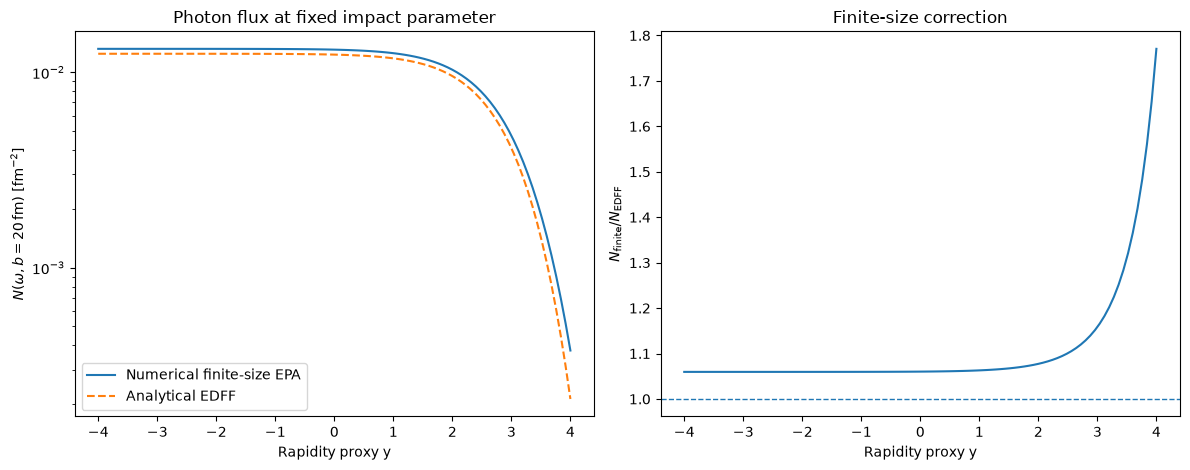

In [9]:
# Comparison versus rapidity at the original illustrative b = 20 fm.
y_edff = np.linspace(CFG.y_report_min, CFG.y_report_max, 101)
omega_edff = rapidity_to_omega(y_edff)
b_edff = 20.0

finite_y = np.array(
    [
        finite_size_epa_flux(float(omega), b_edff, DELTA_R_MEAN_FM, A_MEAN_FM)
        for omega in tqdm(omega_edff, desc="Finite-size vs EDFF at b=20 fm")
    ]
)
edff_y = analytical_edff_flux(omega_edff, b_edff)
ratio_y = finite_y / edff_y

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].semilogy(y_edff, finite_y, label="Numerical finite-size EPA")
axes[0].semilogy(y_edff, edff_y, "--", label="Analytical EDFF")
axes[0].set_xlabel("Rapidity proxy y")
axes[0].set_ylabel(r"$N(\omega,b=20\,\mathrm{fm})$ [fm$^{-2}$]")
axes[0].set_title("Photon flux at fixed impact parameter")
axes[0].legend()

axes[1].plot(y_edff, ratio_y)
axes[1].axhline(1.0, linestyle="--", linewidth=1)
axes[1].set_xlabel("Rapidity proxy y")
axes[1].set_ylabel(r"$N_{\rm finite}/N_{\rm EDFF}$")
axes[1].set_title("Finite-size correction")
plt.tight_layout()
plt.show()

# [auto] save all figures
for _fignum in plt.get_fignums():
    _fig = plt.figure(_fignum)
    _fig.savefig(OUTPUT_DIR / "fig_part05_cell14_n{_fignum}.png", dpi=200, bbox_inches="tight")
    _fig.savefig(OUTPUT_DIR / "fig_part05_cell14_n{_fignum}.pdf", bbox_inches="tight")


b scan at y=-2:   0%|          | 0/70 [00:00<?, ?it/s]

b scan at y=+0:   0%|          | 0/70 [00:00<?, ?it/s]

b scan at y=+2:   0%|          | 0/70 [00:00<?, ?it/s]

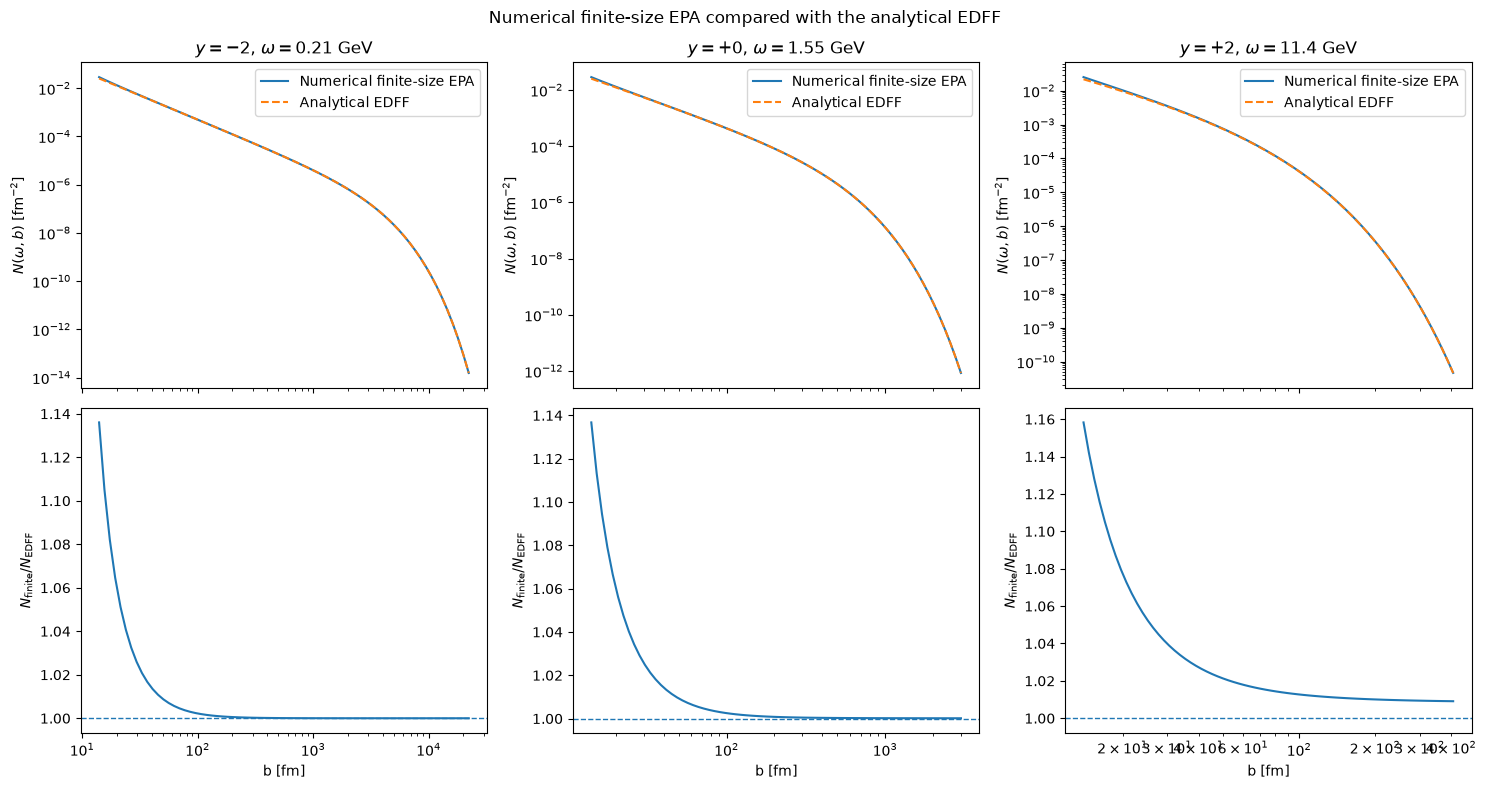

In [10]:
# Comparison versus impact parameter at representative photon energies.
selected_y = [-2.0, 0.0, 2.0]
fig, axes = plt.subplots(2, len(selected_y), figsize=(15, 8), sharex="col")

for column, y_value in enumerate(selected_y):
    omega_value = float(rapidity_to_omega(y_value))
    b_upper = float(b_max_for_omega(omega_value))
    b_values = np.geomspace(CFG.b_min_fm, b_upper, 70)
    finite_values = np.array(
        [
            finite_size_epa_flux(
                omega_value,
                float(b_value),
                DELTA_R_MEAN_FM,
                A_MEAN_FM,
            )
            for b_value in tqdm(b_values, desc=f"b scan at y={y_value:+.0f}")
        ]
    )
    edff_values = analytical_edff_flux(omega_value, b_values)

    axes[0, column].loglog(b_values, finite_values, label="Numerical finite-size EPA")
    axes[0, column].loglog(b_values, edff_values, "--", label="Analytical EDFF")
    axes[0, column].set_title(fr"$y={y_value:+.0f}$, $\omega={omega_value:.3g}$ GeV")
    axes[0, column].set_ylabel(r"$N(\omega,b)$ [fm$^{-2}$]")
    axes[0, column].legend()

    axes[1, column].semilogx(b_values, finite_values / edff_values)
    axes[1, column].axhline(1.0, linestyle="--", linewidth=1)
    axes[1, column].set_xlabel("b [fm]")
    axes[1, column].set_ylabel(r"$N_{\rm finite}/N_{\rm EDFF}$")

plt.suptitle("Numerical finite-size EPA compared with the analytical EDFF")
plt.tight_layout()
plt.show()

# [auto] save all figures
for _fignum in plt.get_fignums():
    _fig = plt.figure(_fignum)
    _fig.savefig(OUTPUT_DIR / "fig_part05_cell15_n{_fignum}.png", dpi=200, bbox_inches="tight")
    _fig.savefig(OUTPUT_DIR / "fig_part05_cell15_n{_fignum}.pdf", bbox_inches="tight")


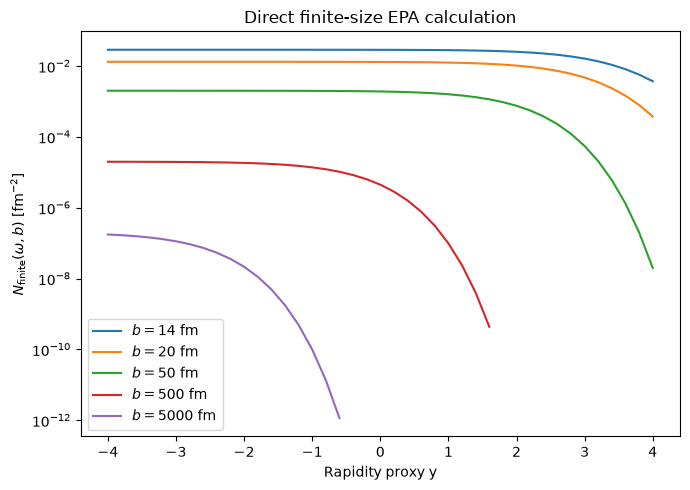

In [11]:
# Basic finite-size flux behaviour over the reported rapidity interval.
y_scan_check = np.linspace(CFG.y_report_min, CFG.y_report_max, 41)
omega_scan_check = rapidity_to_omega(y_scan_check)

plt.figure(figsize=(7, 5))
for b_check in [CFG.b_min_fm, 20.0, 50.0, 500.0, 5000.0]:
    values = [
        finite_size_epa_flux(float(omega), b_check, DELTA_R_MEAN_FM, A_MEAN_FM)
        if b_check <= float(b_max_for_omega(omega)) else np.nan
        for omega in omega_scan_check
    ]
    plt.semilogy(y_scan_check, values, label=fr"$b={b_check:g}$ fm")
plt.xlabel("Rapidity proxy y")
plt.ylabel(r"$N_{\rm finite}(\omega,b)$ [fm$^{-2}$]")
plt.title("Direct finite-size EPA calculation")
plt.legend()
plt.tight_layout()
plt.show()

# [auto] save all figures
for _fignum in plt.get_fignums():
    _fig = plt.figure(_fignum)
    _fig.savefig(OUTPUT_DIR / "fig_part05_cell16_n{_fignum}.png", dpi=200, bbox_inches="tight")
    _fig.savefig(OUTPUT_DIR / "fig_part05_cell16_n{_fignum}.pdf", bbox_inches="tight")


## 6. Sobol sampling and feature transformation

Training uses the padded rapidity interval. Validation and test samples use only the reported interval. All neural-network inputs are transformed with the **training-domain** bounds, so the reported endpoints lie inside the scaled domain rather than at \(\pm1\).


In [12]:
FEATURE_COLUMNS = ["log_omega", "log_b", "delta_r_fm", "a_fm"]


def require_power_of_two(n: int) -> int:
    exponent = int(round(math.log2(n)))
    if 2**exponent != n:
        raise ValueError(f"Sobol sample size must be a power of two, received {n}.")
    return exponent


def sample_physics_domain(
    n: int,
    seed: int,
    *,
    y_min: float,
    y_max: float,
) -> pd.DataFrame:
    exponent = require_power_of_two(n)
    unit = qmc.Sobol(d=4, scramble=True, seed=seed).random_base2(exponent)

    log_omega_min = math.log(float(rapidity_to_omega(y_min)))
    log_omega_max = math.log(float(rapidity_to_omega(y_max)))
    log_omega = log_omega_min + unit[:, 0] * (log_omega_max - log_omega_min)

    omega = np.exp(log_omega)
    log_b_upper = np.log(b_max_for_omega(omega))
    log_b = LOG_B_MIN + unit[:, 1] * (log_b_upper - LOG_B_MIN)

    delta_r = DELTA_R_MIN_FM + unit[:, 2] * (DELTA_R_MAX_FM - DELTA_R_MIN_FM)
    a_values = A_MIN_FM + unit[:, 3] * (A_MAX_FM - A_MIN_FM)

    return pd.DataFrame(
        {
            "log_omega": log_omega,
            "log_b": log_b,
            "delta_r_fm": delta_r,
            "a_fm": a_values,
        }
    )


def transform_features(frame: pd.DataFrame) -> np.ndarray:
    values = frame[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
    lower = np.array([FEATURE_DOMAIN[column][0] for column in FEATURE_COLUMNS], dtype=np.float32)
    upper = np.array([FEATURE_DOMAIN[column][1] for column in FEATURE_COLUMNS], dtype=np.float32)
    transformed = 2.0 * (values - lower) / (upper - lower) - 1.0
    return transformed.astype(np.float32)


example_domain = sample_physics_domain(
    16,
    SEED,
    y_min=CFG.y_train_min,
    y_max=CFG.y_train_max,
)
example_display = example_domain.copy()
example_display.insert(2, "b_fm", np.exp(example_display["log_b"]))
display(example_display.head())
assert np.all(np.abs(transform_features(example_domain)) <= 1.0 + 1.0e-6)
assert np.all(
    np.exp(example_domain["log_b"])
    <= b_max_for_omega(np.exp(example_domain["log_omega"])) * (1.0 + 1.0e-12)
)


,log_omega,log_b,b_fm,delta_r_fm,a_fm
0,-2.318138,4.338404,76.585184,0.141716,0.543713
1,2.146375,6.067446,431.576938,0.363753,0.571130
2,3.599113,3.380469,29.384558,0.264965,0.502316
3,-0.936408,6.425406,617.331458,0.467232,0.567699
4,-0.674994,5.463847,236.003535,0.302271,0.549768


## 7. Generate or load independent Sobol datasets

The direct finite-size integral is the expensive label. The training sample uses the padded domain; validation and test samples use the reported domain. The test sample is not used for fitting, early stopping or MC-dropout calibration.


In [13]:
def evaluate_direct_flux(frame: pd.DataFrame, description: str = "Direct flux") -> np.ndarray:
    flux_values = []
    iterator = tqdm(frame.itertuples(index=False), total=len(frame), desc=description)
    for row in iterator:
        flux_values.append(
            finite_size_epa_flux(
                omega_gev=float(np.exp(row.log_omega)),
                b_fm=float(np.exp(row.log_b)),
                delta_r_fm=float(row.delta_r_fm),
                a_fm=float(row.a_fm),
            )
        )
    flux = np.asarray(flux_values, dtype=np.float64)
    if not np.all(np.isfinite(flux)) or np.any(flux <= 0.0):
        raise FloatingPointError("The direct integrator returned a non-positive or non-finite value.")
    return flux


def edff_flux_for_frame(frame: pd.DataFrame) -> np.ndarray:
    omega = np.exp(frame["log_omega"].to_numpy(dtype=float))
    b_fm = np.exp(frame["log_b"].to_numpy(dtype=float))
    flux = np.asarray(analytical_edff_flux(omega, b_fm), dtype=np.float64)
    if not np.all(np.isfinite(flux)) or np.any(flux <= 0.0):
        raise FloatingPointError("The analytical EDFF returned a non-positive or non-finite value.")
    return flux


CACHE_SIGNATURE = {
    "config": asdict(CFG),
    "target": "log(finite_size_flux / analytical_EDFF_flux)",
    "r0_base_fm": R0_BASE_FM,
    "delta_r_prior": [DELTA_R_MEAN_FM, DELTA_R_SIGMA_FM],
    "a_prior": [A_MEAN_FM, A_SIGMA_FM],
    "gamma": GAMMA_BEAM,
    "z": Z_ION,
    "hbarc": HBARC_GEV_FM,
}
CACHE_TAG = hashlib.sha1(
    json.dumps(CACHE_SIGNATURE, sort_keys=True).encode("utf-8")
).hexdigest()[:10]
print("Dataset cache tag:", CACHE_TAG)


def load_or_create_split(
    name: str,
    n: int,
    seed: int,
    *,
    y_min: float,
    y_max: float,
) -> tuple[pd.DataFrame, np.ndarray, float]:
    cache_path = OUTPUT_DIR / f"{name}_{MODE}_{n}_{CACHE_TAG}.npz"
    if cache_path.exists():
        cached = np.load(cache_path)
        frame = pd.DataFrame(cached["physical"], columns=FEATURE_COLUMNS)
        flux = cached["flux"]
        elapsed = float(cached.get("elapsed_seconds", np.nan))
        print(f"Loaded {name} from {cache_path}")
        return frame, flux, elapsed

    frame = sample_physics_domain(n, seed, y_min=y_min, y_max=y_max)
    start = time.perf_counter()
    flux = evaluate_direct_flux(frame, description=f"Generating {name}")
    elapsed = time.perf_counter() - start
    np.savez_compressed(
        cache_path,
        physical=frame[FEATURE_COLUMNS].to_numpy(),
        flux=flux,
        elapsed_seconds=np.array(elapsed),
    )
    print(f"Generated {name} in {elapsed:.2f} s and cached it at {cache_path}")
    return frame, flux, elapsed


train_frame, train_flux, train_generation_seconds = load_or_create_split(
    "train",
    CFG.n_train,
    SEED + 1,
    y_min=CFG.y_train_min,
    y_max=CFG.y_train_max,
)
val_frame, val_flux, val_generation_seconds = load_or_create_split(
    "validation",
    CFG.n_val,
    SEED + 2,
    y_min=CFG.y_report_min,
    y_max=CFG.y_report_max,
)
test_frame, test_flux, test_generation_seconds = load_or_create_split(
    "test",
    CFG.n_test,
    SEED + 3,
    y_min=CFG.y_report_min,
    y_max=CFG.y_report_max,
)

X_train = transform_features(train_frame)
X_val = transform_features(val_frame)
X_test = transform_features(test_frame)

log_edff_train = np.log(edff_flux_for_frame(train_frame))
log_edff_val = np.log(edff_flux_for_frame(val_frame))
log_edff_test = np.log(edff_flux_for_frame(test_frame))

log_correction_train = np.log(train_flux) - log_edff_train
log_correction_val = np.log(val_flux) - log_edff_val
log_correction_test = np.log(test_flux) - log_edff_test

TRAIN_LABEL_GENERATION_SECONDS = train_generation_seconds if np.isfinite(train_generation_seconds) else 0.0
VALIDATION_LABEL_GENERATION_SECONDS = sum(
    value
    for value in [val_generation_seconds, test_generation_seconds]
    if np.isfinite(value)
)
DATA_GENERATION_SECONDS = TRAIN_LABEL_GENERATION_SECONDS + VALIDATION_LABEL_GENERATION_SECONDS

print("Shapes:", X_train.shape, X_val.shape, X_test.shape)
display(pd.Series(log_correction_train, name="log_finite_over_EDFF").describe())


Dataset cache tag: ff497cbdaf


Generating train:   0%|          | 0/65536 [00:00<?, ?it/s]

Generated train in 435.13 s and cached it at bnn_flux_outputs/train_publication_65536_ff497cbdaf.npz


Generating validation:   0%|          | 0/2048 [00:00<?, ?it/s]

Generated validation in 13.55 s and cached it at bnn_flux_outputs/validation_publication_2048_ff497cbdaf.npz


Generating test:   0%|          | 0/4096 [00:00<?, ?it/s]

Generated test in 27.12 s and cached it at bnn_flux_outputs/test_publication_4096_ff497cbdaf.npz
Shapes: (65536, 4) (2048, 4) (4096, 4)


count    6.553600e+04
mean     9.024079e-02
std      2.139012e-01
min      5.549823e-07
25%      1.184190e-04
50%      4.877773e-03
75%      5.926961e-02
max      1.443152e+00
Name: log_finite_over_EDFF, dtype: float64

## 8. Target scaling and MC-dropout network

The deterministic target is

\[
c=\log(N_{\rm finite}/N_{\rm EDFF}).
\]

The direct integration has no stochastic observation noise, so the network has one output and no learned aleatoric-variance head. Dropout is activated explicitly during MC inference.


Model: "mc_dropout_edff_correction_surrogate"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ scaled_physics_inputs           │ (None, 4)              │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scaled_log_finite_over_edff     │ (None, 1)              │            65 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 108,289 (423.00 KB)

 Trainable params: 108,289 (423.00 KB)

 Non-trainable params: 0 (0.00 B)

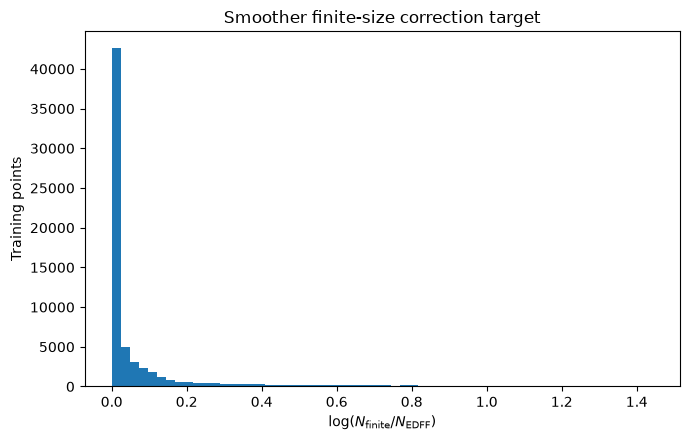

In [14]:
@dataclass
class StandardScaler1D:
    mean: float
    std: float

    @classmethod
    def fit(cls, values: np.ndarray) -> "StandardScaler1D":
        values = np.asarray(values, dtype=float)
        std = float(values.std())
        if std <= 0.0:
            raise ValueError("Target standard deviation must be positive.")
        return cls(mean=float(values.mean()), std=std)

    def transform(self, values: np.ndarray) -> np.ndarray:
        return ((np.asarray(values) - self.mean) / self.std).astype(np.float32)

    def inverse(self, values: np.ndarray) -> np.ndarray:
        return self.mean + self.std * np.asarray(values)


target_scaler = StandardScaler1D.fit(log_correction_train)
y_train = target_scaler.transform(log_correction_train)
y_val = target_scaler.transform(log_correction_val)
y_test = target_scaler.transform(log_correction_test)


def build_surrogate(seed_offset: int = 0) -> keras.Model:
    tf.keras.utils.set_random_seed(SEED + seed_offset)
    inputs = keras.Input(shape=(4,), name="scaled_physics_inputs")
    x = inputs
    for index, units in enumerate(CFG.hidden_units):
        x = layers.Dense(units, activation="swish", name=f"dense_{index + 1}")(x)
        x = layers.Dropout(CFG.dropout_rate, name=f"dropout_{index + 1}")(x)
    outputs = layers.Dense(1, activation=None, name="scaled_log_finite_over_edff")(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="mc_dropout_edff_correction_surrogate")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=CFG.learning_rate),
        loss=keras.losses.Huber(delta=1.0),
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
    )
    return model


model = build_surrogate()
model.summary()

plt.figure(figsize=(7, 4.5))
plt.hist(log_correction_train, bins=60)
plt.xlabel(r"$\log(N_{\rm finite}/N_{\rm EDFF})$")
plt.ylabel("Training points")
plt.title("Smoother finite-size correction target")
plt.tight_layout()
plt.show()

# [auto] save all figures
for _fignum in plt.get_fignums():
    _fig = plt.figure(_fignum)
    _fig.savefig(OUTPUT_DIR / "fig_part08_cell22_n{_fignum}.png", dpi=200, bbox_inches="tight")
    _fig.savefig(OUTPUT_DIR / "fig_part08_cell22_n{_fignum}.pdf", bbox_inches="tight")


## 9. Train with a genuine validation set


In [15]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=CFG.patience,
        restore_best_weights=True,
        min_delta=1.0e-6,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=max(8, CFG.patience // 3),
        min_lr=1.0e-6,
        verbose=1,
    ),
    keras.callbacks.TerminateOnNaN(),
]

start = time.perf_counter()
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=CFG.epochs,
    batch_size=CFG.batch_size,
    callbacks=callbacks,
    verbose=1,
    shuffle=True,
)
TRAINING_SECONDS = time.perf_counter() - start
print(f"Training time: {TRAINING_SECONDS:.2f} s")


Epoch 1/800


error: operand #1 does not dominate this use
E0000 00:00:1792503415.197845 31364243 meta_optimizer.cc:967] tfg_optimizer{any(tfg-consolidate-attrs,tfg-toposort,tfg-shape-inference{graph-version=0},tfg-prepare-attrs-export)} failed: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
W0000 00:00:1792503415.198053 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 



  1/256 ━━━━━━━━━━━━━━━━━━━━ 2:33 602ms/step - loss: 0.2326 - mae: 0.5446


 22/256 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2280 - mae: 0.4904    


 44/256 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2092 - mae: 0.4585

error: operand #0 does not dominate this use
W0000 00:00:1792503415.412743 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


... (4,280 outputs left out)


234/256 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.2351e-04 - mae: 0.0238


252/256 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 8.2003e-04 - mae: 0.0238


256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 8.2329e-04 - mae: 0.0238 - val_loss: 1.7342e-05 - val_mae: 0.0049 - learning_rate: 3.9063e-06


Training time: 199.14 s


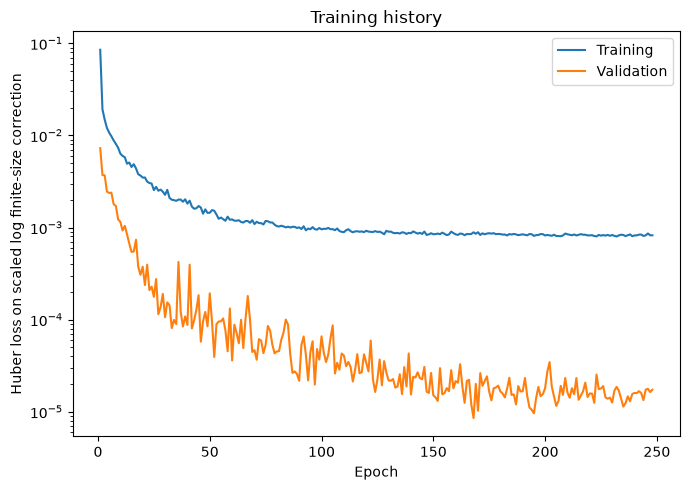

In [16]:
history_frame = pd.DataFrame(history.history)

plt.figure(figsize=(7, 5))
plt.semilogy(history_frame.index + 1, history_frame["loss"], label="Training")
plt.semilogy(history_frame.index + 1, history_frame["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Huber loss on scaled log finite-size correction")
plt.title("Training history")
plt.legend()
plt.tight_layout()
plt.show()

history_frame.to_csv(OUTPUT_DIR / f"training_history_{MODE}.csv", index=False)

# [auto] save all figures
for _fignum in plt.get_fignums():
    _fig = plt.figure(_fignum)
    _fig.savefig(OUTPUT_DIR / "fig_part09_cell25_n{_fignum}.png", dpi=200, bbox_inches="tight")
    _fig.savefig(OUTPUT_DIR / "fig_part09_cell25_n{_fignum}.pdf", bbox_inches="tight")


## 10. Independent multidimensional validation

All reported metrics are calculated on the independent Sobol test set within \(y\in[-4,4]\). Flux predictions are reconstructed by multiplying the analytical EDFF by the learned finite-size correction.


In [17]:
def predict_log_correction_deterministic(
    fitted_model: keras.Model,
    features: np.ndarray,
    scaler: StandardScaler1D,
    batch_size: int = 4096,
) -> np.ndarray:
    scaled = fitted_model.predict(features, batch_size=batch_size, verbose=0).reshape(-1)
    return scaler.inverse(scaled)


def predict_flux_deterministic(
    fitted_model: keras.Model,
    frame: pd.DataFrame,
    scaler: StandardScaler1D,
    batch_size: int = 4096,
) -> np.ndarray:
    features = transform_features(frame)
    log_correction = predict_log_correction_deterministic(
        fitted_model,
        features,
        scaler,
        batch_size=batch_size,
    )
    return edff_flux_for_frame(frame) * np.exp(log_correction)


def residual_summary(direct_flux: np.ndarray, predicted_flux: np.ndarray) -> pd.DataFrame:
    relative = predicted_flux / direct_flux - 1.0
    absolute_relative = np.abs(relative)
    rows = {
        "mean_signed_relative": np.mean(relative),
        "median_absolute_relative": np.median(absolute_relative),
        "p90_absolute_relative": np.quantile(absolute_relative, 0.90),
        "p95_absolute_relative": np.quantile(absolute_relative, 0.95),
        "p99_absolute_relative": np.quantile(absolute_relative, 0.99),
        "maximum_absolute_relative": np.max(absolute_relative),
        "rmse_log_flux": np.sqrt(
            np.mean((np.log(predicted_flux) - np.log(direct_flux)) ** 2)
        ),
    }
    return pd.DataFrame({"metric": rows.keys(), "value": rows.values()})


predicted_flux_test = predict_flux_deterministic(model, test_frame, target_scaler)
relative_residual_test = predicted_flux_test / test_flux - 1.0

metrics_table = residual_summary(test_flux, predicted_flux_test)
display(metrics_table)
metrics_table.to_csv(OUTPUT_DIR / f"test_metrics_{MODE}.csv", index=False)


error: operand #1 does not dominate this use
E0000 00:00:1792505235.017685 31364243 meta_optimizer.cc:967] tfg_optimizer{any(tfg-consolidate-attrs,tfg-toposort,tfg-shape-inference{graph-version=0},tfg-prepare-attrs-export)} failed: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
W0000 00:00:1792505235.017781 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


,metric,value
0,mean_signed_relative,0.000089
1,median_absolute_relative,0.000405
2,p90_absolute_relative,0.001213
3,p95_absolute_relative,0.001633
4,p99_absolute_relative,0.002852
5,maximum_absolute_relative,0.009761
6,rmse_log_flux,0.000883


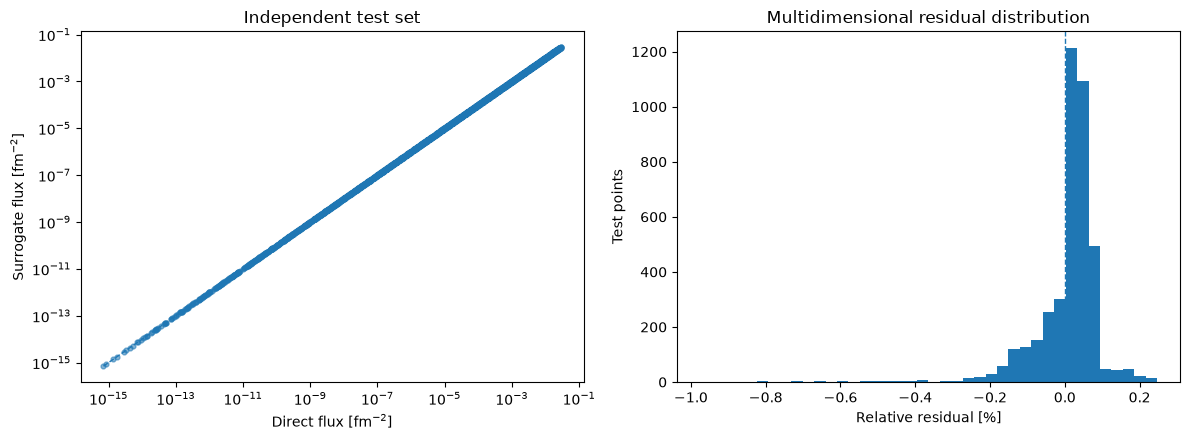

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(test_flux, predicted_flux_test, s=12, alpha=0.55)
minimum = min(test_flux.min(), predicted_flux_test.min())
maximum = max(test_flux.max(), predicted_flux_test.max())
axes[0].plot([minimum, maximum], [minimum, maximum], "--", linewidth=1)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("Direct flux [fm$^{-2}$]")
axes[0].set_ylabel("Surrogate flux [fm$^{-2}$]")
axes[0].set_title("Independent test set")

axes[1].hist(100.0 * relative_residual_test, bins=40)
axes[1].axvline(0.0, linestyle="--", linewidth=1)
axes[1].set_xlabel("Relative residual [%]")
axes[1].set_ylabel("Test points")
axes[1].set_title("Multidimensional residual distribution")

plt.tight_layout()
plt.show()

# [auto] save all figures
for _fignum in plt.get_fignums():
    _fig = plt.figure(_fignum)
    _fig.savefig(OUTPUT_DIR / "fig_part10_cell28_n{_fignum}.png", dpi=200, bbox_inches="tight")
    _fig.savefig(OUTPUT_DIR / "fig_part10_cell28_n{_fignum}.pdf", bbox_inches="tight")


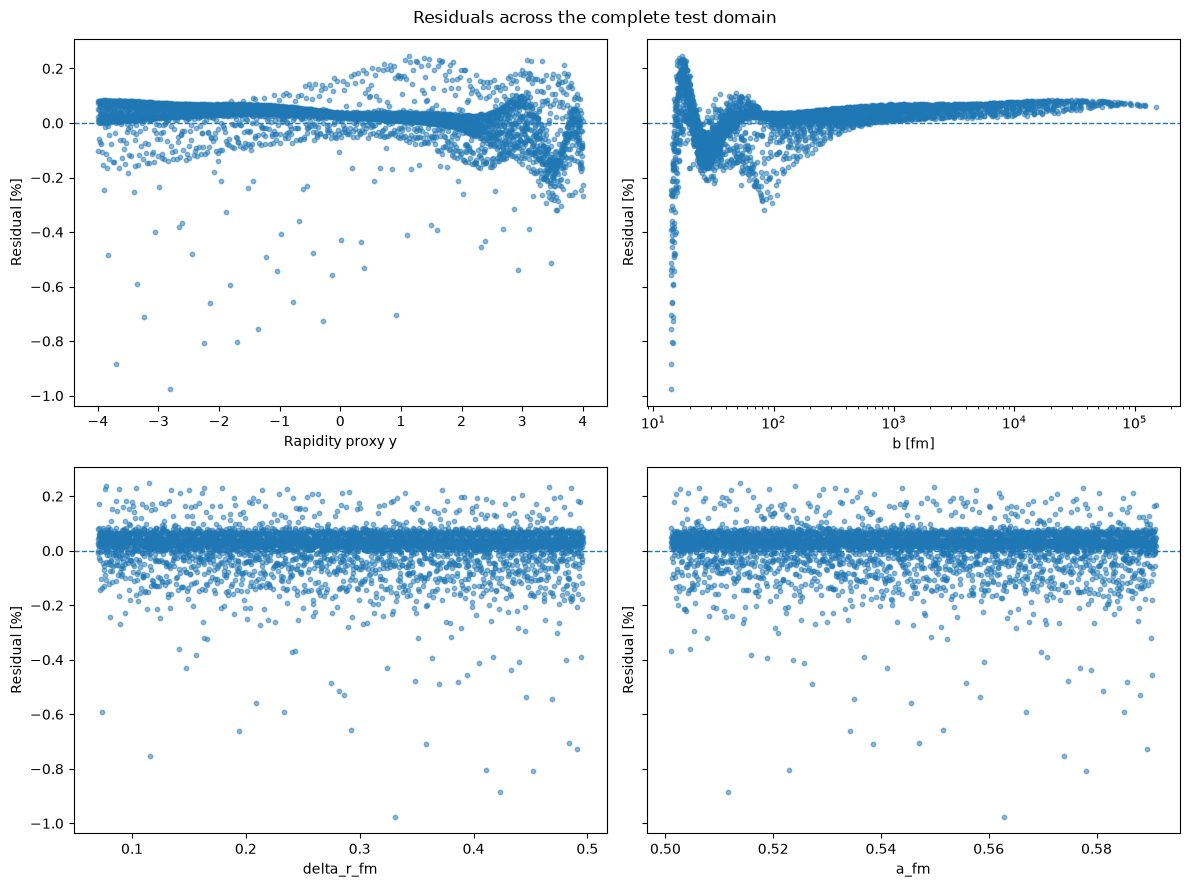

In [19]:
# Residuals against every physical input expose boundary failures hidden by a global histogram.
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)
for axis, column in zip(axes.flat, FEATURE_COLUMNS):
    x_values = test_frame[column].to_numpy()
    if column == "log_omega":
        x_values = omega_to_rapidity(np.exp(x_values))
        x_label = "Rapidity proxy y"
    elif column == "log_b":
        x_values = np.exp(x_values)
        x_label = "b [fm]"
        axis.set_xscale("log")
    else:
        x_label = column
    axis.scatter(x_values, 100.0 * relative_residual_test, s=10, alpha=0.5)
    axis.axhline(0.0, linestyle="--", linewidth=1)
    axis.set_xlabel(x_label)
    axis.set_ylabel("Residual [%]")
plt.suptitle("Residuals across the complete test domain")
plt.tight_layout()
plt.show()

# [auto] save all figures
for _fignum in plt.get_fignums():
    _fig = plt.figure(_fignum)
    _fig.savefig(OUTPUT_DIR / "fig_part10_cell29_n{_fignum}.png", dpi=200, bbox_inches="tight")
    _fig.savefig(OUTPUT_DIR / "fig_part10_cell29_n{_fignum}.pdf", bbox_inches="tight")


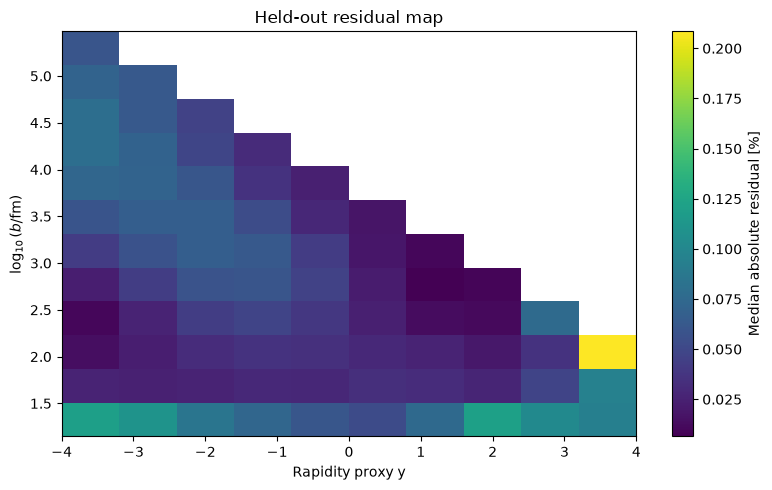

In [20]:
# Binned residual map in rapidity and log10(b). Empty bins outside the xi-limited domain remain blank.
y_test_physical = omega_to_rapidity(np.exp(test_frame["log_omega"].to_numpy()))
log10_b_test = test_frame["log_b"].to_numpy() / np.log(10.0)

n_y_bins = 10
n_b_bins = 12
y_edges = np.linspace(CFG.y_report_min, CFG.y_report_max, n_y_bins + 1)
log10_b_edges = np.linspace(np.log10(CFG.b_min_fm), np.log10(CFG.b_hard_max_fm), n_b_bins + 1)
heatmap = np.full((n_b_bins, n_y_bins), np.nan)

for iy in range(n_y_bins):
    for ib in range(n_b_bins):
        mask = (
            (y_test_physical >= y_edges[iy])
            & (y_test_physical < y_edges[iy + 1])
            & (log10_b_test >= log10_b_edges[ib])
            & (log10_b_test < log10_b_edges[ib + 1])
        )
        if np.any(mask):
            heatmap[ib, iy] = 100.0 * np.median(np.abs(relative_residual_test[mask]))

plt.figure(figsize=(8, 5))
image = plt.imshow(
    heatmap,
    origin="lower",
    aspect="auto",
    extent=[CFG.y_report_min, CFG.y_report_max, log10_b_edges[0], log10_b_edges[-1]],
)
plt.colorbar(image, label="Median absolute residual [%]")
plt.xlabel("Rapidity proxy y")
plt.ylabel(r"$\log_{10}(b/\mathrm{fm})$")
plt.title("Held-out residual map")
plt.tight_layout()
plt.show()

# [auto] save all figures
for _fignum in plt.get_fignums():
    _fig = plt.figure(_fignum)
    _fig.savefig(OUTPUT_DIR / "fig_part10_cell30_n{_fignum}.png", dpi=200, bbox_inches="tight")
    _fig.savefig(OUTPUT_DIR / "fig_part10_cell30_n{_fignum}.pdf", bbox_inches="tight")


## 11. MC-dropout epistemic uncertainty and calibration

Repeated calls with `training=True` produce samples of the learned log correction. The analytical EDFF is deterministic, so calibration can be performed directly in correction space. The calibration factor is fitted only on the validation set and then frozen.


In [21]:
def mc_dropout_log_correction_samples(
    fitted_model: keras.Model,
    features: np.ndarray,
    scaler: StandardScaler1D,
    *,
    n_passes: int,
) -> np.ndarray:
    samples = []
    tensor = tf.convert_to_tensor(features, dtype=tf.float32)
    for _ in range(n_passes):
        scaled_prediction = fitted_model(tensor, training=True).numpy().reshape(-1)
        samples.append(scaler.inverse(scaled_prediction))
    return np.asarray(samples)


def fit_dropout_spread_scale(
    true_log_correction: np.ndarray,
    log_correction_samples: np.ndarray,
) -> float:
    mean = log_correction_samples.mean(axis=0)
    variance = log_correction_samples.var(axis=0, ddof=1)
    valid = variance > 1.0e-12
    if not np.any(valid):
        raise RuntimeError("MC-dropout variance is numerically zero.")
    scale = np.sqrt(
        np.mean(
            (true_log_correction[valid] - mean[valid]) ** 2
            / variance[valid]
        )
    )
    return float(scale)


def scale_mc_samples(samples: np.ndarray, factor: float) -> np.ndarray:
    centre = samples.mean(axis=0, keepdims=True)
    return centre + factor * (samples - centre)


def correction_samples_to_flux(
    frame: pd.DataFrame,
    log_correction_samples: np.ndarray,
) -> np.ndarray:
    log_edff = np.log(edff_flux_for_frame(frame))
    return np.exp(log_correction_samples + log_edff[None, :])


val_log_correction_samples_raw = mc_dropout_log_correction_samples(
    model,
    X_val,
    target_scaler,
    n_passes=CFG.mc_passes,
)
DROPOUT_SPREAD_SCALE = fit_dropout_spread_scale(
    log_correction_val,
    val_log_correction_samples_raw,
)
print(f"Validation-fitted MC-dropout spread scale: {DROPOUT_SPREAD_SCALE:.3f}")

test_log_correction_samples_raw = mc_dropout_log_correction_samples(
    model,
    X_test,
    target_scaler,
    n_passes=CFG.mc_passes,
)
test_log_correction_samples_calibrated = scale_mc_samples(
    test_log_correction_samples_raw,
    DROPOUT_SPREAD_SCALE,
)
test_flux_samples_calibrated = correction_samples_to_flux(
    test_frame,
    test_log_correction_samples_calibrated,
)


Validation-fitted MC-dropout spread scale: 0.171


,nominal_coverage,empirical_coverage,interval
0,0.50,0.996094,raw MC dropout
1,0.68,0.999268,raw MC dropout
2,0.90,1.000000,raw MC dropout
3,0.95,1.000000,raw MC dropout
4,0.50,0.430420,validation calibrated
5,0.68,0.675781,validation calibrated
6,0.90,0.941895,validation calibrated
7,0.95,0.969238,validation calibrated


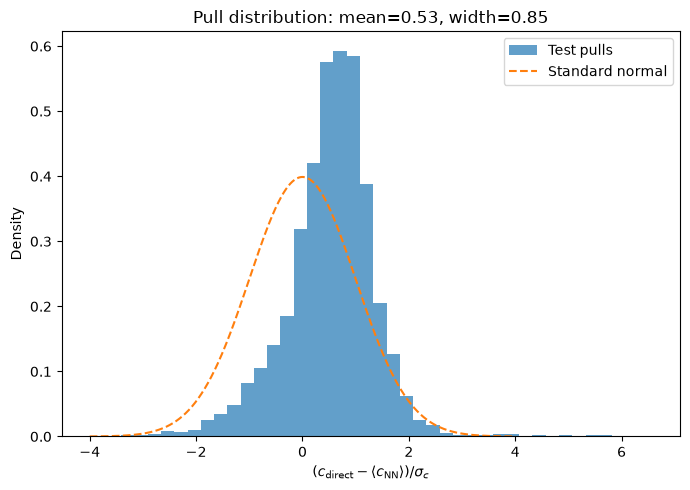

In [22]:
def empirical_coverage_table(true_values: np.ndarray, samples: np.ndarray) -> pd.DataFrame:
    rows = []
    for nominal in [0.50, 0.68, 0.90, 0.95]:
        tail = 0.5 * (1.0 - nominal)
        lower = np.quantile(samples, tail, axis=0)
        upper = np.quantile(samples, 1.0 - tail, axis=0)
        empirical = np.mean((true_values >= lower) & (true_values <= upper))
        rows.append({"nominal_coverage": nominal, "empirical_coverage": empirical})
    return pd.DataFrame(rows)


coverage_raw = empirical_coverage_table(
    log_correction_test,
    test_log_correction_samples_raw,
)
coverage_raw["interval"] = "raw MC dropout"

coverage_calibrated = empirical_coverage_table(
    log_correction_test,
    test_log_correction_samples_calibrated,
)
coverage_calibrated["interval"] = "validation calibrated"

coverage_table = pd.concat([coverage_raw, coverage_calibrated], ignore_index=True)
display(coverage_table)
coverage_table.to_csv(OUTPUT_DIR / f"coverage_{MODE}.csv", index=False)

calibrated_mean = test_log_correction_samples_calibrated.mean(axis=0)
calibrated_std = test_log_correction_samples_calibrated.std(axis=0, ddof=1)
pulls = (
    log_correction_test - calibrated_mean
) / np.maximum(calibrated_std, 1.0e-12)

plt.figure(figsize=(7, 5))
plt.hist(pulls, bins=40, density=True, alpha=0.7, label="Test pulls")
x_pull = np.linspace(-4.0, 4.0, 400)
plt.plot(x_pull, norm.pdf(x_pull), "--", label="Standard normal")
plt.xlabel(
    r"$(c_{\rm direct}-\langle c_{\rm NN}\rangle)/\sigma_c$"
)
plt.ylabel("Density")
plt.title(
    f"Pull distribution: mean={pulls.mean():.2f}, "
    f"width={pulls.std(ddof=1):.2f}"
)
plt.legend()
plt.tight_layout()
plt.show()

# [auto] save all figures
for _fignum in plt.get_fignums():
    _fig = plt.figure(_fignum)
    _fig.savefig(OUTPUT_DIR / "fig_part11_cell33_n{_fignum}.png", dpi=200, bbox_inches="tight")
    _fig.savefig(OUTPUT_DIR / "fig_part11_cell33_n{_fignum}.pdf", bbox_inches="tight")


## 12. Nuclear-parameter uncertainty: direct numerical validation and decomposition

Before relying on the surrogate for physical uncertainty propagation, the nuclear contribution is checked directly with the numerical integrator at five rapidities and \(b=20\) fm.

At fixed kinematics \(x=(\omega,b)\), the total variance is then decomposed as

\[
\sigma_{\rm epi}^2
=
\mathbb{E}_{\phi}\left[\mathrm{Var}_{t}(N_{t,\phi})\right],
\qquad
\sigma_{\rm nuc}^2
=
\mathrm{Var}_{\phi}\left[\mathbb{E}_{t}(N_{t,\phi})\right],
\]

where \(\phi=(\Delta R,a)\) and \(t\) labels MC-dropout realisations.


In [23]:
def sample_truncated_nuclear_prior(
    n: int,
    seed: int,
) -> tuple[np.ndarray, np.ndarray]:
    rng = np.random.default_rng(seed)
    delta_r_values = []
    a_values = []
    while len(delta_r_values) < n:
        draw_delta = rng.normal(DELTA_R_MEAN_FM, DELTA_R_SIGMA_FM, size=n)
        draw_a = rng.normal(A_MEAN_FM, A_SIGMA_FM, size=n)
        accepted = (
            (draw_delta >= DELTA_R_MIN_FM)
            & (draw_delta <= DELTA_R_MAX_FM)
            & (draw_a >= A_MIN_FM)
            & (draw_a <= A_MAX_FM)
        )
        delta_r_values.extend(draw_delta[accepted].tolist())
        a_values.extend(draw_a[accepted].tolist())
    return np.asarray(delta_r_values[:n]), np.asarray(a_values[:n])


def nuclear_prior_frame(
    omega_gev: float,
    b_fm: float,
    *,
    n: int,
    seed: int,
) -> pd.DataFrame:
    delta_r, a_values = sample_truncated_nuclear_prior(n, seed)
    return pd.DataFrame(
        {
            "log_omega": np.full(n, np.log(omega_gev)),
            "log_b": np.full(n, np.log(b_fm)),
            "delta_r_fm": delta_r,
            "a_fm": a_values,
        }
    )


def uncertainty_decomposition_at_kinematics(
    omega_gev: float,
    b_fm: float,
    *,
    n_nuclear: int,
    n_dropout: int,
    seed: int,
) -> dict[str, float]:
    frame = nuclear_prior_frame(
        omega_gev,
        b_fm,
        n=n_nuclear,
        seed=seed,
    )
    features = transform_features(frame)
    raw_samples = mc_dropout_log_correction_samples(
        model,
        features,
        target_scaler,
        n_passes=n_dropout,
    )
    calibrated_samples = scale_mc_samples(
        raw_samples,
        DROPOUT_SPREAD_SCALE,
    )
    flux_samples = correction_samples_to_flux(frame, calibrated_samples)

    conditional_means = flux_samples.mean(axis=0)
    conditional_variances = flux_samples.var(axis=0, ddof=1)
    epistemic_variance = float(np.mean(conditional_variances))
    nuclear_variance = float(np.var(conditional_means, ddof=1))
    total_variance = epistemic_variance + nuclear_variance

    central = float(np.mean(conditional_means))
    return {
        "central": central,
        "sigma_epistemic": math.sqrt(max(epistemic_variance, 0.0)),
        "sigma_nuclear": math.sqrt(max(nuclear_variance, 0.0)),
        "sigma_total": math.sqrt(max(total_variance, 0.0)),
    }


Direct nuclear-uncertainty validation:   0%|          | 0/5 [00:00<?, ?it/s]

Direct nuclear labels y=-4.0:   0%|          | 0/256 [00:00<?, ?it/s]

error: operand #1 does not dominate this use
W0000 00:00:1792505243.845063 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


Direct nuclear labels y=-2.0:   0%|          | 0/256 [00:00<?, ?it/s]

Direct nuclear labels y=+0.0:   0%|          | 0/256 [00:00<?, ?it/s]

Direct nuclear labels y=+2.0:   0%|          | 0/256 [00:00<?, ?it/s]

Direct nuclear labels y=+4.0:   0%|          | 0/256 [00:00<?, ?it/s]

,y,direct_mean,surrogate_mean,mean_relative_residual,direct_nuclear_relative,surrogate_nuclear_relative,nuclear_sigma_relative_residual
0,-4.0,0.013171,0.013171,-0.000008,0.001134,0.001180,0.040748
1,-2.0,0.013168,0.013172,0.000342,0.001113,0.001150,0.033419
2,0.0,0.013045,0.013062,0.001267,0.001132,0.001179,0.041907
3,2.0,0.010293,0.010302,0.000865,0.001550,0.001618,0.043951
4,4.0,0.000377,0.000376,-0.001619,0.010117,0.009909,-0.020544


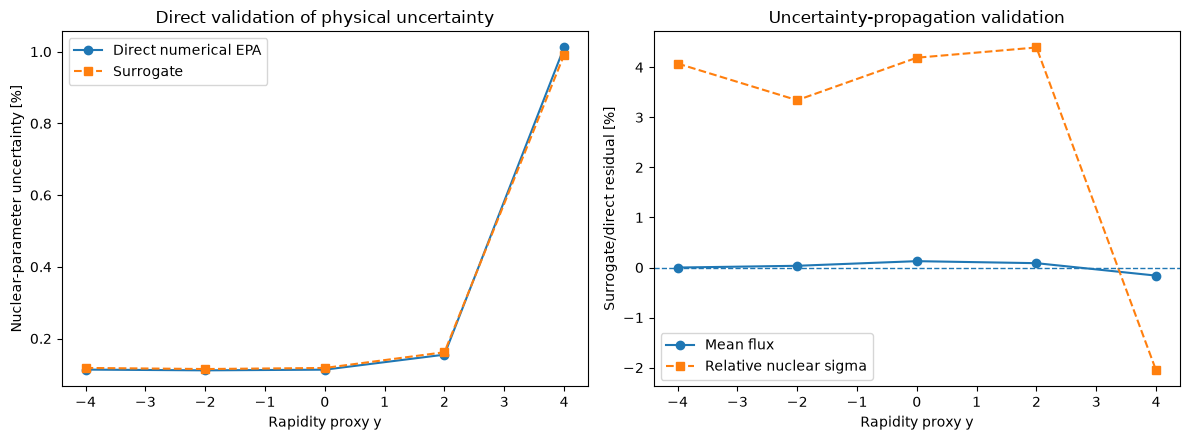

In [24]:
# Direct numerical validation of the nuclear-parameter component.
direct_nuclear_rows = []
direct_validation_y = np.linspace(
    CFG.y_report_min,
    CFG.y_report_max,
    5,
)

for index, y_value in enumerate(
    tqdm(direct_validation_y, desc="Direct nuclear-uncertainty validation")
):
    omega_value = float(rapidity_to_omega(y_value))
    frame = nuclear_prior_frame(
        omega_value,
        20.0,
        n=CFG.nuclear_direct_validation_samples,
        seed=SEED + 15000 + index,
    )
    direct_values = evaluate_direct_flux(
        frame,
        description=f"Direct nuclear labels y={y_value:+.1f}",
    )
    surrogate_values = predict_flux_deterministic(
        model,
        frame,
        target_scaler,
    )

    direct_mean = float(np.mean(direct_values))
    direct_sigma = float(np.std(direct_values, ddof=1))
    surrogate_mean = float(np.mean(surrogate_values))
    surrogate_sigma = float(np.std(surrogate_values, ddof=1))

    direct_nuclear_rows.append(
        {
            "y": y_value,
            "direct_mean": direct_mean,
            "surrogate_mean": surrogate_mean,
            "mean_relative_residual": surrogate_mean / direct_mean - 1.0,
            "direct_nuclear_relative": direct_sigma / direct_mean,
            "surrogate_nuclear_relative": surrogate_sigma / surrogate_mean,
            "nuclear_sigma_relative_residual": (
                surrogate_sigma / surrogate_mean
            ) / (direct_sigma / direct_mean) - 1.0,
        }
    )

direct_nuclear_validation = pd.DataFrame(direct_nuclear_rows)
display(direct_nuclear_validation)
direct_nuclear_validation.to_csv(
    OUTPUT_DIR / f"direct_nuclear_validation_{MODE}.csv",
    index=False,
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(
    direct_nuclear_validation["y"],
    100.0 * direct_nuclear_validation["direct_nuclear_relative"],
    "o-",
    label="Direct numerical EPA",
)
axes[0].plot(
    direct_nuclear_validation["y"],
    100.0 * direct_nuclear_validation["surrogate_nuclear_relative"],
    "s--",
    label="Surrogate",
)
axes[0].set_xlabel("Rapidity proxy y")
axes[0].set_ylabel("Nuclear-parameter uncertainty [%]")
axes[0].set_title("Direct validation of physical uncertainty")
axes[0].legend()

axes[1].plot(
    direct_nuclear_validation["y"],
    100.0 * direct_nuclear_validation["mean_relative_residual"],
    "o-",
    label="Mean flux",
)
axes[1].plot(
    direct_nuclear_validation["y"],
    100.0 * direct_nuclear_validation["nuclear_sigma_relative_residual"],
    "s--",
    label="Relative nuclear sigma",
)
axes[1].axhline(0.0, linestyle="--", linewidth=1)
axes[1].set_xlabel("Rapidity proxy y")
axes[1].set_ylabel("Surrogate/direct residual [%]")
axes[1].set_title("Uncertainty-propagation validation")
axes[1].legend()
plt.tight_layout()
plt.show()

# [auto] save all figures
for _fignum in plt.get_fignums():
    _fig = plt.figure(_fignum)
    _fig.savefig(OUTPUT_DIR / "fig_part12_cell36_n{_fignum}.png", dpi=200, bbox_inches="tight")
    _fig.savefig(OUTPUT_DIR / "fig_part12_cell36_n{_fignum}.pdf", bbox_inches="tight")


Uncertainty decomposition:   0%|          | 0/31 [00:00<?, ?it/s]

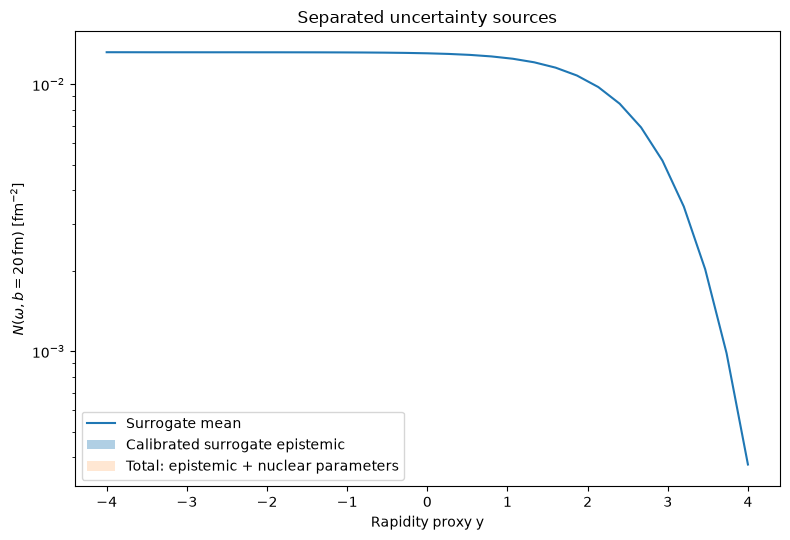

,y,epistemic_relative,nuclear_relative,total_relative
count,3.100000e+01,31.000000,31.000000,31.000000
mean,-2.005564e-16,0.001040,0.002091,0.002357
std,2.424566e+00,0.000492,0.002048,0.002080
min,-4.000000e+00,0.000697,0.001197,0.001390
25%,-2.000000e+00,0.000751,0.001271,0.001506
50%,0.000000e+00,0.000866,0.001304,0.001586
75%,2.000000e+00,0.001074,0.001567,0.001752
max,4.000000e+00,0.002759,0.010679,0.011030


In [25]:
# Rapidity scan at b = 20 fm with separated uncertainties.
y_uncertainty = np.linspace(
    CFG.y_report_min,
    CFG.y_report_max,
    31,
)
uncertainty_rows = []

for index, y_value in enumerate(
    tqdm(y_uncertainty, desc="Uncertainty decomposition")
):
    result = uncertainty_decomposition_at_kinematics(
        float(rapidity_to_omega(y_value)),
        20.0,
        n_nuclear=CFG.uncertainty_nuclear_samples,
        n_dropout=CFG.mc_passes,
        seed=SEED + 5000 + index,
    )
    result["y"] = y_value
    uncertainty_rows.append(result)

uncertainty_frame = pd.DataFrame(uncertainty_rows)
uncertainty_frame.to_csv(
    OUTPUT_DIR / f"uncertainty_decomposition_{MODE}.csv",
    index=False,
)


def plot_band(axis, x, centre, sigma, label, alpha):
    lower = np.maximum(centre - sigma, np.finfo(float).tiny)
    upper = centre + sigma
    axis.fill_between(x, lower, upper, alpha=alpha, label=label)


fig, axis = plt.subplots(figsize=(8, 5.5))
axis.plot(
    uncertainty_frame["y"],
    uncertainty_frame["central"],
    label="Surrogate mean",
)
plot_band(
    axis,
    uncertainty_frame["y"].to_numpy(),
    uncertainty_frame["central"].to_numpy(),
    uncertainty_frame["sigma_epistemic"].to_numpy(),
    "Calibrated surrogate epistemic",
    0.35,
)
plot_band(
    axis,
    uncertainty_frame["y"].to_numpy(),
    uncertainty_frame["central"].to_numpy(),
    uncertainty_frame["sigma_total"].to_numpy(),
    "Total: epistemic + nuclear parameters",
    0.18,
)
axis.set_yscale("log")
axis.set_xlabel("Rapidity proxy y")
axis.set_ylabel(r"$N(\omega,b=20\,\mathrm{fm})$ [fm$^{-2}$]")
axis.set_title("Separated uncertainty sources")
axis.legend()
plt.tight_layout()
plt.show()

relative_uncertainty_table = pd.DataFrame(
    {
        "y": uncertainty_frame["y"],
        "epistemic_relative": (
            uncertainty_frame["sigma_epistemic"]
            / uncertainty_frame["central"]
        ),
        "nuclear_relative": (
            uncertainty_frame["sigma_nuclear"]
            / uncertainty_frame["central"]
        ),
        "total_relative": (
            uncertainty_frame["sigma_total"]
            / uncertainty_frame["central"]
        ),
    }
)
display(relative_uncertainty_table.describe())

# [auto] save all figures
for _fignum in plt.get_fignums():
    _fig = plt.figure(_fignum)
    _fig.savefig(OUTPUT_DIR / "fig_part12_cell37_n{_fignum}.png", dpi=200, bbox_inches="tight")
    _fig.savefig(OUTPUT_DIR / "fig_part12_cell37_n{_fignum}.pdf", bbox_inches="tight")


## 13. Sobol sample-size convergence

The safest replacement for the unsupported active-learning claim is a controlled Sobol scaling study. It reuses nested prefixes of the same 8192-point Sobol training set, so no additional direct-integrator labels are required.

The key question is whether both held-out error and calibrated epistemic uncertainty flatten between 4096 and 8192 points. If they do not, the final sample should be increased to 16384 in a subsequent run.


error: operand #1 does not dominate this use
E0000 00:00:1792505681.920297 31364243 meta_optimizer.cc:967] tfg_optimizer{any(tfg-consolidate-attrs,tfg-toposort,tfg-shape-inference{graph-version=0},tfg-prepare-attrs-export)} failed: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
W0000 00:00:1792505681.920447 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


error: operand #0 does not dominate this use
W0000 00:00:1792505682.147619 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
error: operand #0 does not dominate this use
W0000 00:00:1792505682.287271 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


error: operand #1 does not dominate this use
W0000 00:00:1792505701.342462 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


error: operand #1 does not dominate this use
W0000 00:00:1792505704.763183 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


error: operand #0 does not dominate this use
W0000 00:00:1792505704.982436 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
error: operand #0 does not dominate this use
W0000 00:00:1792505705.131188 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


error: operand #1 does not dominate this use
W0000 00:00:1792505727.550932 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


... (13 outputs left out)

error: operand #0 does not dominate this use
W0000 00:00:1792506070.724021 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


error: operand #1 does not dominate this use
E0000 00:00:1792506580.519276 31364243 meta_optimizer.cc:967] tfg_optimizer{any(tfg-consolidate-attrs,tfg-toposort,tfg-shape-inference{graph-version=0},tfg-prepare-attrs-export)} failed: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
W0000 00:00:1792506580.519383 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


error: operand #1 does not dominate this use
W0000 00:00:1792506583.438036 31364243 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


,n_train,median_absolute_relative,p95_absolute_relative,p99_absolute_relative,median_epistemic_relative,p90_epistemic_relative,dropout_spread_scale,training_seconds
0,1024,0.006186,0.027088,0.053953,0.012307,0.018330,1.002078,19.720096
1,2048,0.005721,0.025735,0.049993,0.010687,0.017527,0.980398,23.091801
2,4096,0.002436,0.017330,0.032308,0.004815,0.009405,0.582236,39.149479
3,8192,0.000719,0.007419,0.017999,0.002048,0.004035,0.288409,49.932323
4,16384,0.000873,0.003222,0.009000,0.001194,0.002319,0.201426,86.273466
5,32768,0.000734,0.002300,0.005062,0.001304,0.002505,0.238753,103.189965
6,65536,0.000405,0.001633,0.002852,0.000857,0.001726,0.194521,199.143346


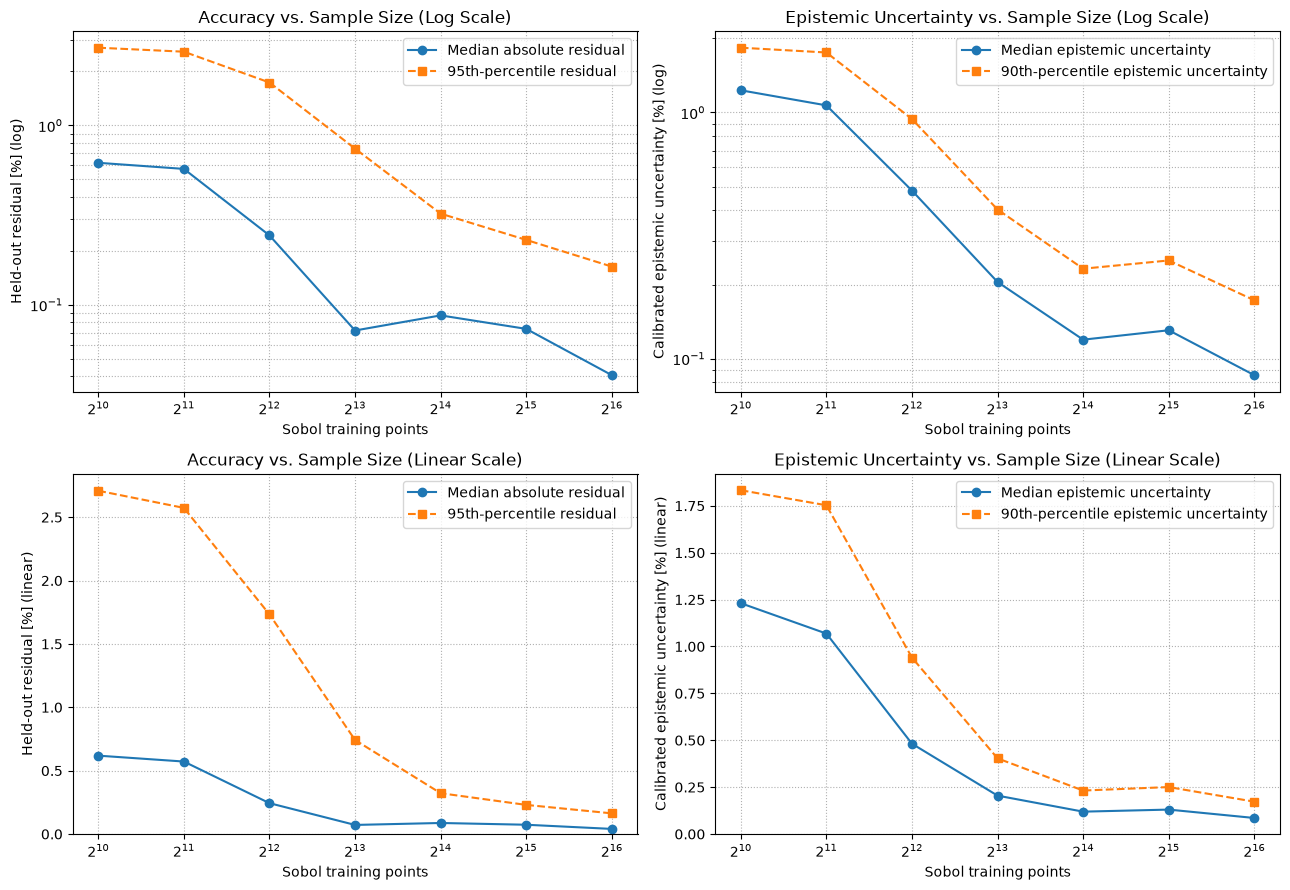

Fractional change from the penultimate to final Sobol sample: p95 error=0.290, median epistemic=0.343
The scaling has not clearly flattened at 65536 points. Add a 131072-point Sobol run before fixing the manuscript sample.


In [26]:
def train_subset_model(
    n_train_subset: int,
    *,
    seed_offset: int,
) -> tuple[keras.Model, StandardScaler1D, float]:
    subset_scaler = StandardScaler1D.fit(
        log_correction_train[:n_train_subset]
    )
    subset_model = build_surrogate(seed_offset=seed_offset)
    subset_callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=CFG.patience,
            restore_best_weights=True,
            min_delta=1.0e-6,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=max(8, CFG.patience // 4),
            min_lr=1.0e-6,
            verbose=0,
        ),
        keras.callbacks.TerminateOnNaN(),
    ]

    start = time.perf_counter()
    subset_model.fit(
        X_train[:n_train_subset],
        subset_scaler.transform(
            log_correction_train[:n_train_subset]
        ),
        validation_data=(
            X_val,
            subset_scaler.transform(log_correction_val),
        ),
        epochs=CFG.sample_size_study_epochs,
        batch_size=CFG.batch_size,
        callbacks=subset_callbacks,
        verbose=0,
        shuffle=True,
    )
    elapsed = time.perf_counter() - start
    return subset_model, subset_scaler, elapsed


sample_size_rows = []

if CFG.run_sample_size_study:
    for index, sample_size in enumerate(CFG.sample_size_study_sizes):
        if sample_size == CFG.n_train:
            subset_model = model
            subset_scaler = target_scaler
            training_seconds = TRAINING_SECONDS
        else:
            subset_model, subset_scaler, training_seconds = train_subset_model(
                sample_size,
                seed_offset=0,
            )

        subset_prediction = predict_flux_deterministic(
            subset_model,
            test_frame,
            subset_scaler,
        )
        summary = residual_summary(
            test_flux,
            subset_prediction,
        ).set_index("metric")["value"]

        val_samples_raw = mc_dropout_log_correction_samples(
            subset_model,
            X_val,
            subset_scaler,
            n_passes=CFG.sample_size_mc_passes,
        )
        subset_scale = fit_dropout_spread_scale(
            log_correction_val,
            val_samples_raw,
        )

        test_samples_raw = mc_dropout_log_correction_samples(
            subset_model,
            X_test,
            subset_scaler,
            n_passes=CFG.sample_size_mc_passes,
        )
        test_samples_calibrated = scale_mc_samples(
            test_samples_raw,
            subset_scale,
        )
        flux_samples = correction_samples_to_flux(
            test_frame,
            test_samples_calibrated,
        )
        relative_epistemic = (
            flux_samples.std(axis=0, ddof=1)
            / flux_samples.mean(axis=0)
        )

        sample_size_rows.append(
            {
                "n_train": sample_size,
                "median_absolute_relative": summary[
                    "median_absolute_relative"
                ],
                "p95_absolute_relative": summary[
                    "p95_absolute_relative"
                ],
                "p99_absolute_relative": summary[
                    "p99_absolute_relative"
                ],
                "median_epistemic_relative": np.median(
                    relative_epistemic
                ),
                "p90_epistemic_relative": np.quantile(
                    relative_epistemic,
                    0.90,
                ),
                "dropout_spread_scale": subset_scale,
                "training_seconds": training_seconds,
            }
        )

    sample_size_table = pd.DataFrame(sample_size_rows)
    display(sample_size_table)
    sample_size_table.to_csv(
        OUTPUT_DIR / f"sobol_sample_size_study_{MODE}.csv",
        index=False,
    )

# 2x2 layout: Top row = Log y-scale, Bottom row = Non-log (Linear) y-scale
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))

    # --- Row 0: Original Log-Scale Y ---
    axes[0, 0].plot(
        sample_size_table["n_train"],
        100.0 * sample_size_table["median_absolute_relative"],
        "o-",
        label="Median absolute residual",
    )
    axes[0, 0].plot(
        sample_size_table["n_train"],
        100.0 * sample_size_table["p95_absolute_relative"],
        "s--",
        label="95th-percentile residual",
    )
    axes[0, 0].set_xscale("log", base=2)
    axes[0, 0].set_yscale("log")
    axes[0, 0].set_xlabel("Sobol training points")
    axes[0, 0].set_ylabel("Held-out residual [%] (log)")
    axes[0, 0].set_title("Accuracy vs. Sample Size (Log Scale)")
    axes[0, 0].legend()
    axes[0, 0].grid(True, which="both", ls=":")

    axes[0, 1].plot(
        sample_size_table["n_train"],
        100.0 * sample_size_table["median_epistemic_relative"],
        "o-",
        label="Median epistemic uncertainty",
    )
    axes[0, 1].plot(
        sample_size_table["n_train"],
        100.0 * sample_size_table["p90_epistemic_relative"],
        "s--",
        label="90th-percentile epistemic uncertainty",
    )
    axes[0, 1].set_xscale("log", base=2)
    axes[0, 1].set_yscale("log")
    axes[0, 1].set_xlabel("Sobol training points")
    axes[0, 1].set_ylabel("Calibrated epistemic uncertainty [%] (log)")
    axes[0, 1].set_title("Epistemic Uncertainty vs. Sample Size (Log Scale)")
    axes[0, 1].legend()
    axes[0, 1].grid(True, which="both", ls=":")

    # --- Row 1: Non-Log (Linear) Y-Scale ---
    axes[1, 0].plot(
        sample_size_table["n_train"],
        100.0 * sample_size_table["median_absolute_relative"],
        "o-",
        label="Median absolute residual",
    )
    axes[1, 0].plot(
        sample_size_table["n_train"],
        100.0 * sample_size_table["p95_absolute_relative"],
        "s--",
        label="95th-percentile residual",
    )
    axes[1, 0].set_xscale("log", base=2)
    axes[1, 0].set_yscale("linear")
    axes[1, 0].set_ylim(bottom=0)
    axes[1, 0].set_xlabel("Sobol training points")
    axes[1, 0].set_ylabel("Held-out residual [%] (linear)")
    axes[1, 0].set_title("Accuracy vs. Sample Size (Linear Scale)")
    axes[1, 0].legend()
    axes[1, 0].grid(True, ls=":")

    axes[1, 1].plot(
        sample_size_table["n_train"],
        100.0 * sample_size_table["median_epistemic_relative"],
        "o-",
        label="Median epistemic uncertainty",
    )
    axes[1, 1].plot(
        sample_size_table["n_train"],
        100.0 * sample_size_table["p90_epistemic_relative"],
        "s--",
        label="90th-percentile epistemic uncertainty",
    )
    axes[1, 1].set_xscale("log", base=2)
    axes[1, 1].set_yscale("linear")
    axes[1, 1].set_ylim(bottom=0)
    axes[1, 1].set_xlabel("Sobol training points")
    axes[1, 1].set_ylabel("Calibrated epistemic uncertainty [%] (linear)")
    axes[1, 1].set_title("Epistemic Uncertainty vs. Sample Size (Linear Scale)")
    axes[1, 1].legend()
    axes[1, 1].grid(True, ls=":")

    plt.tight_layout()
    plt.show()

    if len(sample_size_table) >= 2:
        previous = sample_size_table.iloc[-2]
        final = sample_size_table.iloc[-1]
        p95_change = abs(
            final["p95_absolute_relative"]
            / previous["p95_absolute_relative"]
            - 1.0
        )
        epistemic_change = abs(
            final["median_epistemic_relative"]
            / previous["median_epistemic_relative"]
            - 1.0
        )
        print(
            "Fractional change from the penultimate to final Sobol sample:",
            f"p95 error={p95_change:.3f},",
            f"median epistemic={epistemic_change:.3f}",
        )
        if p95_change < 0.10 and epistemic_change < 0.10:
            print(
                f"{CFG.n_train} points are provisionally near the observed plateau. "
                "Confirm with at least three training seeds."
            )
        else:
            print(
                f"The scaling has not clearly flattened at {CFG.n_train} points. "
                f"Add a {2 * CFG.n_train}-point Sobol run before fixing the manuscript sample."
            )
else:
    print("Sobol sample-size study disabled in CFG.")

# [auto] save all figures
for _fignum in plt.get_fignums():
    _fig = plt.figure(_fignum)
    _fig.savefig(OUTPUT_DIR / "fig_part13_cell39_n{_fignum}.png", dpi=200, bbox_inches="tight")
    _fig.savefig(OUTPUT_DIR / "fig_part13_cell39_n{_fignum}.pdf", bbox_inches="tight")


## 14. Analysis-level demonstration: impact-parameter-integrated flux

Compare

\[
n_{\rm finite}(\omega)
=
2\pi\int_{b_{\min}}^{b_{\max}(\omega)}
b\,db\,N_{\rm finite}(\omega,b)
\]

from direct numerical integration and from the surrogate. The analytical EDFF integral is included as a physics baseline.

The lower boundary remains a sharp UPC cutoff. Before using this result in a production cross section, replace it with the same no-hadronic-interaction probability used by the analysis framework.


In [4]:
def integrated_flux_direct(
    omega_gev: float,
    *,
    xi_max: float | None = None,
    n_b: int = CFG.integrated_b_nodes,
) -> float:
    b_upper = float(b_max_for_omega(omega_gev, xi_max=xi_max))
    log_b_nodes, log_b_weights = gauss_legendre_interval(
        np.log(CFG.b_min_fm),
        np.log(b_upper),
        n_b,
    )
    b_nodes = np.exp(log_b_nodes)
    differential = np.array(
        [
            finite_size_epa_flux(
                omega_gev,
                float(b_value),
                DELTA_R_MEAN_FM,
                A_MEAN_FM,
            )
            for b_value in b_nodes
        ]
    )
    return float(
        2.0 * np.pi
        * np.sum(log_b_weights * b_nodes**2 * differential)
    )


def integrated_flux_surrogate(
    omega_gev: float,
    *,
    n_b: int = CFG.integrated_b_nodes,
) -> float:
    b_upper = float(b_max_for_omega(omega_gev))
    log_b_nodes, log_b_weights = gauss_legendre_interval(
        np.log(CFG.b_min_fm),
        np.log(b_upper),
        n_b,
    )
    b_nodes = np.exp(log_b_nodes)
    frame = pd.DataFrame(
        {
            "log_omega": np.full(n_b, np.log(omega_gev)),
            "log_b": log_b_nodes,
            "delta_r_fm": np.full(n_b, DELTA_R_MEAN_FM),
            "a_fm": np.full(n_b, A_MEAN_FM),
        }
    )
    flux = predict_flux_deterministic(
        model,
        frame,
        target_scaler,
    )
    return float(
        2.0 * np.pi
        * np.sum(log_b_weights * b_nodes**2 * flux)
    )


y_integrated = np.linspace(
    CFG.y_report_min,
    CFG.y_report_max,
    CFG.integrated_y_points,
)
integrated_rows = []

for y_value in tqdm(
    y_integrated,
    desc="Integrated-flux comparison",
):
    omega_value = float(rapidity_to_omega(y_value))
    direct_value = integrated_flux_direct(omega_value)
    surrogate_value = integrated_flux_surrogate(omega_value)
    edff_value = float(
        analytical_edff_integrated_flux(omega_value)
    )
    integrated_rows.append(
        {
            "y": y_value,
            "omega_gev": omega_value,
            "direct_finite": direct_value,
            "surrogate_finite": surrogate_value,
            "analytical_EDFF": edff_value,
            "surrogate_relative_residual": (
                surrogate_value / direct_value - 1.0
            ),
            "finite_to_EDFF": direct_value / edff_value,
        }
    )

integrated_table = pd.DataFrame(integrated_rows)
display(integrated_table)
integrated_table.to_csv(
    OUTPUT_DIR / f"integrated_flux_{MODE}.csv",
    index=False,
)


NameError: name 'CFG' is not defined

In [3]:
# Direct-integral stability against the Bessel-tail cutoff.
cutoff_rows = []
for y_value in [CFG.y_report_min, 0.0, CFG.y_report_max]:
    omega_value = float(rapidity_to_omega(y_value))
    for xi_cut in [6.0, 8.0, 10.0]:
        cutoff_rows.append(
            {
                "y": y_value,
                "xi_max": xi_cut,
                "b_max_fm": float(
                    b_max_for_omega(
                        omega_value,
                        xi_max=xi_cut,
                    )
                ),
                "integrated_direct": integrated_flux_direct(
                    omega_value,
                    xi_max=xi_cut,
                ),
            }
        )

cutoff_convergence = pd.DataFrame(cutoff_rows)
cutoff_convergence["relative_to_xi10"] = (
    cutoff_convergence.groupby("y")["integrated_direct"]
    .transform(lambda values: values / values.iloc[-1] - 1.0)
)
display(cutoff_convergence)
cutoff_convergence.to_csv(
    OUTPUT_DIR / f"integrated_cutoff_convergence_{MODE}.csv",
    index=False,
)


NameError: name 'CFG' is not defined

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].semilogy(
    integrated_table["y"],
    integrated_table["direct_finite"],
    "o-",
    label="Direct finite-size EPA",
)
axes[0].semilogy(
    integrated_table["y"],
    integrated_table["surrogate_finite"],
    "s--",
    label="Surrogate finite-size EPA",
)
axes[0].semilogy(
    integrated_table["y"],
    integrated_table["analytical_EDFF"],
    ":",
    label="Analytical EDFF",
)
axes[0].set_xlabel("Rapidity proxy y")
axes[0].set_ylabel(r"$n(\omega)$")
axes[0].set_title("Impact-parameter-integrated flux")
axes[0].legend()

axes[1].plot(
    integrated_table["y"],
    100.0 * integrated_table["surrogate_relative_residual"],
    "b-",
    label="Surrogate/direct finite-size",
)
axes[1].plot(
    integrated_table["y"],
    100.0 * (integrated_table["finite_to_EDFF"] - 1.0),
    "g--",
    label="Direct finite-size/EDFF",
)
axes[1].axhline(0.0, linestyle="--", linewidth=1)
axes[1].set_xlabel("Rapidity proxy y")
axes[1].set_ylabel("Relative difference [%]")
axes[1].set_title("Analysis-level validation and finite-size effect")
axes[1].legend()

plt.tight_layout()
plt.show()

# [auto] save all figures
for _fignum in plt.get_fignums():
    _fig = plt.figure(_fignum)
    _fig.savefig(OUTPUT_DIR / "fig_part14_cell43_n{_fignum}.png", dpi=200, bbox_inches="tight")
    _fig.savefig(OUTPUT_DIR / "fig_part14_cell43_n{_fignum}.pdf", bbox_inches="tight")


NameError: name 'plt' is not defined

## 15. Transparent speed benchmark

The timing benchmark measures the **complete** surrogate evaluation, including feature transformation, network inference, analytical EDFF evaluation and flux reconstruction.


In [5]:
benchmark_frame = sample_physics_domain(
    32,
    SEED + 12000,
    y_min=CFG.y_report_min,
    y_max=CFG.y_report_max,
)

start = time.perf_counter()
_ = evaluate_direct_flux(
    benchmark_frame,
    description="Direct timing",
)
direct_elapsed = time.perf_counter() - start
direct_seconds_per_point = direct_elapsed / len(benchmark_frame)

large_benchmark_frame = sample_physics_domain(
    16384,
    SEED + 12001,
    y_min=CFG.y_report_min,
    y_max=CFG.y_report_max,
).iloc[:10000].reset_index(drop=True)

_ = predict_flux_deterministic(
    model,
    large_benchmark_frame.iloc[:32],
    target_scaler,
)

single_frame = large_benchmark_frame.iloc[:1].copy()
single_repetitions = 100
start = time.perf_counter()
for _ in range(single_repetitions):
    _ = predict_flux_deterministic(
        model,
        single_frame,
        target_scaler,
        batch_size=1,
    )
single_surrogate_seconds = (
    time.perf_counter() - start
) / single_repetitions

start = time.perf_counter()
_ = predict_flux_deterministic(
    model,
    large_benchmark_frame,
    target_scaler,
    batch_size=4096,
)
batch_elapsed = time.perf_counter() - start
batch_surrogate_seconds_per_point = (
    batch_elapsed / len(large_benchmark_frame)
)

operational_upfront_cost = (
    TRAIN_LABEL_GENERATION_SECONDS
    + TRAINING_SECONDS
)
full_study_upfront_cost = (
    DATA_GENERATION_SECONDS
    + TRAINING_SECONDS
)
saved_per_batched_evaluation = max(
    direct_seconds_per_point
    - batch_surrogate_seconds_per_point,
    0.0,
)

operational_break_even = (
    operational_upfront_cost / saved_per_batched_evaluation
    if saved_per_batched_evaluation > 0.0
    else np.inf
)
full_study_break_even = (
    full_study_upfront_cost / saved_per_batched_evaluation
    if saved_per_batched_evaluation > 0.0
    else np.inf
)

benchmark_table = pd.DataFrame(
    {
        "quantity": [
            "direct seconds per point",
            "complete surrogate seconds per point (single call)",
            "complete surrogate seconds per point (batch=10000)",
            "training-label generation seconds",
            "validation+test label generation seconds",
            "training seconds",
            "direct/surrogate speed ratio (single call)",
            "direct/surrogate speed ratio (batched)",
            "operational break-even evaluations",
            "full-study break-even evaluations",
        ],
        "value": [
            direct_seconds_per_point,
            single_surrogate_seconds,
            batch_surrogate_seconds_per_point,
            TRAIN_LABEL_GENERATION_SECONDS,
            VALIDATION_LABEL_GENERATION_SECONDS,
            TRAINING_SECONDS,
            direct_seconds_per_point / single_surrogate_seconds,
            direct_seconds_per_point / batch_surrogate_seconds_per_point,
            operational_break_even,
            full_study_break_even,
        ],
    }
)

display(benchmark_table)
benchmark_table.to_csv(
    OUTPUT_DIR / f"timing_benchmark_{MODE}.csv",
    index=False,
)


NameError: name 'sample_physics_domain' is not defined

## 16. Save the reproducible model package

The manuscript must still contain the architecture and hyperparameter table directly. The saved model and metadata are supplementary reproducibility material.


In [31]:
model_path = (
    OUTPUT_DIR
    / f"mc_dropout_edff_correction_surrogate_{MODE}.keras"
)
model.save(model_path)

metadata = {
    "run_config": asdict(CFG),
    "seed": SEED,
    "cache_tag": CACHE_TAG,
    "feature_columns": FEATURE_COLUMNS,
    "feature_domain": FEATURE_DOMAIN,
    "target_definition": (
        "log(finite_size_EPA_flux / analytical_EDFF_flux)"
    ),
    "target_scaler": asdict(target_scaler),
    "dropout_spread_scale": DROPOUT_SPREAD_SCALE,
    "physics_constants": {
        "alpha_em": ALPHA_EM,
        "z_ion": Z_ION,
        "gamma_beam": GAMMA_BEAM,
        "hbarc_gev_fm": HBARC_GEV_FM,
        "m_jpsi_gev": M_JPSI_GEV,
        "r0_base_fm": R0_BASE_FM,
        "delta_r_mean_fm": DELTA_R_MEAN_FM,
        "delta_r_sigma_fm": DELTA_R_SIGMA_FM,
        "a_mean_fm": A_MEAN_FM,
        "a_sigma_fm": A_SIGMA_FM,
    },
    "software": {
        "python": sys.version,
        "numpy": np.__version__,
        "scipy": scipy.__version__,
        "tensorflow": tf.__version__,
        "platform": platform.platform(),
    },
}

with open(
    OUTPUT_DIR / f"model_metadata_{MODE}.json",
    "w",
) as stream:
    json.dump(metadata, stream, indent=2)

print("Saved model:", model_path)
print("Output directory:", OUTPUT_DIR.resolve())


Saved model: bnn_flux_outputs/mc_dropout_edff_correction_surrogate_publication.keras
Output directory: /Users/jamesnovak/Downloads/bnn_flux_outputs


## 17. Student deliverables and resubmission checklist

### Numerical physics and EDFF baseline

- [ ] Explain every input, output and unit.
- [ ] Verify the \(\hbar c\) convention against the manuscript and reference implementation.
- [ ] Explain why the projected density is renormalised for every \((R_0,a)\).
- [ ] Reproduce the density-normalisation and quadrature-convergence tables.
- [ ] Derive the analytical EDFF expression and its integrated form.
- [ ] Explain the numerical finite-size/EDFF ratio versus \(y\) and \(b\).

### Main Sobol surrogate

- [ ] Explain why the network learns \(\log(N_{\rm finite}/N_{\rm EDFF})\), rather than the complete flux.
- [ ] Explain why training is padded to \([-4.5,4.5]\) while results are reported over \([-4,4]\).
- [ ] Keep training, validation and test sets independent.
- [ ] Report median, 90th, 95th and 99th-percentile residuals and the worst case.
- [ ] Inspect residuals against every input and in the \((y,b)\) heatmap.

### Training-sample decision

- [ ] Run the nested Sobol study for 1024, 2048, 4096 and 8192 points.
- [ ] Check whether both the 95th-percentile error and calibrated epistemic uncertainty flatten by 8192 points.
- [ ] If they do not flatten, repeat the final run with 16384 training points.
- [ ] Repeat the final chosen configuration for at least three random seeds before quoting a manuscript number.
- [ ] Do not make an active-learning efficiency claim.

### Uncertainty

- [ ] Report raw and validation-calibrated MC-dropout coverage.
- [ ] Report the pull mean and width.
- [ ] Validate the nuclear-parameter uncertainty directly with the numerical integrator.
- [ ] Show surrogate epistemic, nuclear-parameter and total uncertainties separately.
- [ ] Check stability against the number of dropout and nuclear samples.
- [ ] Keep the diffuseness prior consistent with the manuscript: \(a=0.546\pm0.015\) fm.

### Physics application and timing

- [ ] Validate the impact-parameter-integrated finite-size flux.
- [ ] Compare the integrated finite-size result with the analytical EDFF.
- [ ] Replace the sharp lower cutoff by the production no-hadronic-interaction probability before calculating a cross section.
- [ ] Demonstrate stability against \(\xi_{\max}\), the hard \(b\) ceiling and the log-\(b\) quadrature order.
- [ ] Record direct-evaluation, label-generation, training and complete-inference times separately.
- [ ] Quote one clearly defined batched speedup and its break-even point.

### Scope boundary

A defensible first resubmission is one Pb--Pb beam configuration with a thoroughly validated four-dimensional finite-size correction surrogate and one integrated-flux application. Do not claim generalisation to other ions or beam energies until those variables are explicitly trained and tested.
